# Hockey project: 3. Classification: in-season coach changes

Task (b): which teams will change their head coach during the regular season? We predict it the day before the season starts, using only information available then.

*FEUP Master, Machine Learning. Notebook 3 of 4 (before: 1_eda, 2_regression; next: 4_feature_selection). Tasks (a) and (c), the team ranking and the penalty minutes per player, are regression tasks and are in notebook 2.*

**Contents**

| Section | Topic | CRISP-DM phase |
|---|---|---|
| 1 | Goal, data and metrics for imbalanced data | Modeling |
| 2 | Baselines | Modeling |
| 3 | Seven algorithms | Modeling |
| 4 | Imbalance handling inside the folds, and why SMOTE on the whole data leaks | Data preparation / modeling |
| 5 | Tuning, validation curves and the model choice | Modeling |
| 6 | Threshold selection | Modeling |
| 7 | Comparison on the evaluation seasons, significance tests | Evaluation |
| 8 | Overfitting analysis and learning curve | Evaluation |
| 9 | Model improvement | Modeling |
| 10 | Feature importance | Evaluation |
| 11 | White-box model | Evaluation |
| 12 | Final test on 2009 | Evaluation |
| 13 | Conclusion | |

Each section says what we do and why, then shows the code and what we found. Where we had to choose something, the decision is written at the end of the section.

**Validation design (the same as in notebook 2)**
- Rolling origin, one season ahead, expanding window: to predict season *s* we train on all seasons from 1967 to *s - 1* and predict the whole season *s* (there is no 2004 season).
- **Tuning seasons 1995-2001**: every choice (imbalance strategy, parameters, model, threshold) is made here. **Evaluation seasons 2002-2008**: only used to compare and test the chosen models. **2009** is the final test, used once in section 12.
- Imputation, scaling and resampling are steps of one imblearn pipeline, fitted on the training seasons of each fold only. All 27 features are used; feature selection is notebook 4. Seeds are fixed to 0.

## 1. Goal, data and metrics for imbalanced data

Load the modeling table from notebook 1, look at the class balance in each group of seasons and how the change rate moves over time, and define the metrics.

About one team in five changes coach during a season, so the classes are imbalanced. A model that always answers "no change" is right four times out of five and finds no change at all, so accuracy is misleading and we do not use it.

| Metric | What it measures | Why we use it |
|---|---|---|
| PR-AUC (average precision), **primary** | How well the real changes are ranked above the other teams; a random ranking scores about the prevalence | Looks only at the rare class, which is the one that matters. Reported **pooled** over all seasons and as a **mean per season** |
| ROC-AUC | Chance that a changing team gets a higher score than a non-changing one (0.5 = random) | Standard, but it can look good when positives are few |
| Precision, recall, F1 | Quality of the flagged teams at a threshold | Needed to turn scores into a watch list; the threshold is chosen on the tuning seasons (section 6) |
| Brier score | Mean squared error of the probabilities (lower is better) | Checks whether the probabilities themselves can be trusted |
| Precision@k, recall@k | Each season we flag the k riskiest teams, k = the expected number of changes (training prevalence x teams) | The natural watch list: "the k teams most likely to change coach" |
| Top-quarter share | Share of all real changes that fall in the riskiest quarter of each season's teams | The G2 criterion of notebook 1 |

**Success criterion G2** (notebook 1): PR-AUC at least 1.25 times the prevalence, and the riskiest quarter of the teams contains at least 40% of the real changes.

Seasons 1967-2008: 908 team-seasons, 191 coach changes (21.0%)


,number of seasons,team-seasons,changes,prevalence
seasons,,,,
tuning 1995-2001,7,193,37,0.192
evaluation 2002-2008,6,180,36,0.200


Mean change rate: 1967-1979 0.259, 1980-1994 0.198, 1995-2008 0.195 (lowest 0.115, highest 0.269)


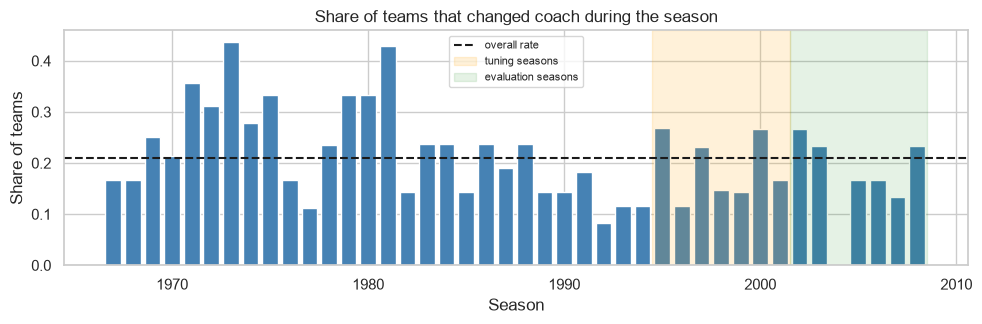

In [1]:
import os, time, warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also silences warnings in the parallel worker processes (section 3)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve, brier_score_loss, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

SEED = 0
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

# Modeling table from notebook 1: one row per team and season, features from season t-1
ROOT = next((p for p in [Path('.'), Path('..')] if (p / 'data' / 'processed').exists()), None)
assert ROOT is not None, 'data/processed not found next to the notebook or one level above it'
d = pd.read_csv(ROOT / 'data' / 'processed' / 'modeling_table.csv')
TARGET = 'target_coach_change'
FEATURES = [c for c in d.columns if (c.startswith(('prev_', 'coach_')) or c == 'has_prev') and c not in ('prev_year', 'prev_gap')]
assert len(FEATURES) == 27 and not any('target' in c for c in FEATURES)
validation = [int(s) for s in sorted(d.loc[d['split'] == 'validation', 'year'].unique())]
TUNE = [s for s in validation if s <= 2001]
EVAL = [s for s in validation if s >= 2002]
TEST = 2009

known = d[d['year'] <= 2008]
print(f"Seasons 1967-2008: {len(known)} team-seasons, {int(known[TARGET].sum())} coach changes ({known[TARGET].mean():.1%})")
rows = []
for label, seasons in [('tuning 1995-2001', TUNE), ('evaluation 2002-2008', EVAL)]:
    part = d[d['year'].isin(seasons)]
    rows.append({'seasons': label, 'number of seasons': len(seasons), 'team-seasons': len(part),
                 'changes': int(part[TARGET].sum()), 'prevalence': part[TARGET].mean()})
display(pd.DataFrame(rows).set_index('seasons').round(3))

rate = known.groupby('year')[TARGET].mean()
print(f"Mean change rate: 1967-1979 {rate.loc[:1979].mean():.3f}, 1980-1994 {rate.loc[1980:1994].mean():.3f}, "
      f"1995-2008 {rate.loc[1995:].mean():.3f} (lowest {rate.loc[1995:].min():.3f}, highest {rate.loc[1995:].max():.3f})")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(rate.index, rate.values, color='steelblue')
ax.axhline(known[TARGET].mean(), color='k', ls='--', label='overall rate')
ax.axvspan(1994.5, 2001.5, color='orange', alpha=0.15, label='tuning seasons')
ax.axvspan(2001.5, 2008.5, color='green', alpha=0.10, label='evaluation seasons')
ax.set(title='Share of teams that changed coach during the season', xlabel='Season', ylabel='Share of teams')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What we found:** From 1967 to 2008 there are 908 team-seasons and 191 in-season coach changes (21.0%). The tuning seasons have 193 team-seasons with 37 changes (prevalence 0.192) and the evaluation seasons 180 with 36 changes (0.200). The change rate drifts over time: 0.259 on average in 1967-1979, 0.198 in 1980-1994 and 0.195 since 1995 (between 0.115 and 0.269 per season).

**Interpretation:** a model trained on old seasons meets a different base rate in recent ones, one more reason to judge the ranking (PR-AUC) and to choose thresholds on recent seasons. With only 36 changes in the evaluation seasons every metric is noisy: one more or one less change found moves the recall by almost 3 points.

**Decision:** primary metric pooled PR-AUC (random level about 0.20), with the mean per season, precision@k, the top-quarter share, F1 and the Brier score as support. Accuracy is not used.

## 2. Baselines

Five reference predictors that need no real learning, scored with the same seasons and metrics as the models:

1. **Majority class (no change):** every team gets probability 0. It has high accuracy and finds nothing.
2. **Constant prevalence:** every team gets the training prevalence; the reference for the Brier score.
3. **Stratified random:** random answers with the training prevalence; the "no skill" case for precision and recall.
4. **Rule: low last-season points:** rank teams by last season's points per game, worst first (poor results get coaches fired). It gives a ranking, not a probability.
5. **Logistic regression on last-season points only:** the same idea with probabilities. This is the hard reference: a model must add something beyond "bad last season".

The code also defines the metrics of section 1. Precision@k and the top-quarter share count the real changes among the k highest scores of each season; teams tied at the cut-off share the remaining places, so constant predictions get the random-flagging value.

In [2]:
def hits_at(pred, k):
    # Expected number of real changes among the k highest scores of one season (ties at the cut-off share the places)
    p, y = pred['p'].values, pred['y'].values
    cut = np.sort(p)[::-1][k - 1]
    above, tied = p > cut, p == cut
    return y[above].sum() + (k - above.sum()) * y[tied].mean()


def scores(pred, threshold=None):
    # All metrics for the predictions of several seasons (columns year, y, p, k)
    seasons = [g for _, g in pred.groupby('year')]
    ap_season = [average_precision_score(g['y'], g['p']) for g in seasons]
    hits_k = sum(hits_at(g, int(g['k'].iloc[0])) for g in seasons)
    flagged_k = sum(int(g['k'].iloc[0]) for g in seasons)
    hits_quarter = sum(hits_at(g, round(len(g) / 4)) for g in seasons)
    changes = pred['y'].sum()
    out = {'PR-AUC pooled': average_precision_score(pred['y'], pred['p']),
           'PR-AUC mean': np.mean(ap_season), 'PR-AUC sd': np.std(ap_season, ddof=1) if len(seasons) > 1 else np.nan,
           'ROC-AUC': roc_auc_score(pred['y'], pred['p']),
           'Brier': brier_score_loss(pred['y'], pred['p']) if pred['p'].between(0, 1).all() else np.nan,
           'P@k': hits_k / flagged_k, 'R@k': hits_k / changes, 'top-quarter share': hits_quarter / changes}
    if threshold is not None:
        flag = pred['p'] >= threshold
        tp = (flag & (pred['y'] == 1)).sum()
        precision = tp / flag.sum() if flag.sum() > 0 else 0.0
        recall = tp / changes
        out.update({'threshold': threshold, 'flagged': flag.mean(), 'precision': precision, 'recall': recall,
                    'F1': 2 * precision * recall / (precision + recall) if tp > 0 else 0.0})
    return out


def baseline_predictions(season):
    # The five baselines for one season, trained on all earlier seasons
    train, test = d[d['year'] < season], d[d['year'] == season]
    y_train = train[TARGET]
    ppg_train, ppg_test = train[['baseline_prev_ppg']], test[['baseline_prev_ppg']]
    one_feature = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression())
    random_guess = DummyClassifier(strategy='stratified', random_state=SEED).fit(np.zeros((len(train), 1)), y_train)
    p = {'Majority (no change)': np.zeros(len(test)),
         'Constant prevalence': np.full(len(test), y_train.mean()),
         'Stratified random': random_guess.predict_proba(np.zeros((len(test), 1)))[:, 1],
         'Rule: low last-season points': -ppg_test['baseline_prev_ppg'].fillna(ppg_train['baseline_prev_ppg'].median()).values,
         'Logistic: last-season points': one_feature.fit(ppg_train, y_train).predict_proba(ppg_test)[:, 1]}
    k = round(y_train.mean() * len(test))
    return {name: pd.DataFrame({'year': season, 'y': test[TARGET].values, 'p': values, 'k': k}, index=test.index)
            for name, values in p.items()}


BASELINES = ['Majority (no change)', 'Constant prevalence', 'Stratified random', 'Rule: low last-season points', 'Logistic: last-season points']
base_tune = {b: [] for b in BASELINES}
base_eval = {b: [] for b in BASELINES}
for season in TUNE + EVAL:
    target = base_tune if season in TUNE else base_eval
    for name, pred in baseline_predictions(season).items():
        target[name].append(pred)
base_tune = {b: pd.concat(v) for b, v in base_tune.items()}
base_eval = {b: pd.concat(v) for b, v in base_eval.items()}

COLS = ['PR-AUC pooled', 'PR-AUC mean', 'PR-AUC sd', 'ROC-AUC', 'Brier', 'P@k', 'top-quarter share']
print('Tuning seasons 1995-2001')
display(pd.DataFrame({b: scores(p) for b, p in base_tune.items()}).T[COLS].round(3))
print('Evaluation seasons 2002-2008')
display(pd.DataFrame({b: scores(p) for b, p in base_eval.items()}).T[COLS].round(3))

Tuning seasons 1995-2001


,PR-AUC pooled,PR-AUC mean,PR-AUC sd,ROC-AUC,Brier,P@k,top-quarter share
Majority (no change),0.192,0.191,0.063,0.500,0.192,0.191,0.249
Constant prevalence,0.181,0.191,0.063,0.466,0.156,0.191,0.249
Stratified random,0.198,0.210,0.053,0.519,0.378,0.209,0.265
Rule: low last-season points,0.237,0.284,0.142,0.547,NaN,0.190,0.270
Logistic: last-season points,0.233,0.284,0.142,0.543,0.156,0.190,0.270


Evaluation seasons 2002-2008


,PR-AUC pooled,PR-AUC mean,PR-AUC sd,ROC-AUC,Brier,P@k,top-quarter share
Majority (no change),0.200,0.200,0.052,0.500,0.200,0.200,0.267
Constant prevalence,0.195,0.200,0.052,0.488,0.160,0.200,0.267
Stratified random,0.207,0.222,0.057,0.521,0.367,0.222,0.296
Rule: low last-season points,0.324,0.392,0.151,0.592,NaN,0.306,0.306
Logistic: last-season points,0.310,0.392,0.151,0.589,0.157,0.306,0.306


**What we found:** On the evaluation seasons the no-skill baselines have a pooled PR-AUC of about 0.20 (majority 0.200, constant prevalence 0.195, random 0.207). The rule on last season's points reaches 0.324 and the one-feature logistic regression 0.310 (0.392 ± 0.151 per season, ROC-AUC 0.589). Both flag 30.6% real changes among their k riskiest teams (random: 0.200), and their riskiest quarter holds 30.6% of all changes (random: 26.7%). The logistic baseline's Brier score (0.157) is barely below the constant prevalence (0.160). On the tuning seasons the same two baselines are much weaker (0.237 and 0.233).

**Interpretation:** a poor last season does predict a coach change, but only weakly, and more clearly in the recent seasons. The rule and the logistic baseline rank the teams of a season in the same order (one feature), so their per-season PR-AUC is identical; only the pooled value differs, because it also compares teams of different seasons.

**Decision:** the one-feature logistic regression is the baseline to beat: it is simple, gives probabilities, and is the comparison in all tests of section 7.

## 3. Seven algorithms

Run seven classifiers with very different language bias (the kind of boundary they can draw) with their default parameters on the tuning seasons.

If the risk of a coach change grows smoothly with bad results, a linear model is enough; if it depends on combinations (a new coach *and* a bad season), trees are better; if similar teams behave alike, k-NN. Comparing them tells us something about the structure of the problem.

| Algorithm | What it can represent | Key parameters |
|---|---|---|
| Logistic regression | Linear log-odds: one weight per feature, smooth monotone effects | `C`: small C shrinks the weights (simpler model) |
| Decision tree | Yes/no rules on single features, with interactions | `max_depth`, `min_samples_leaf`: deep trees with small leaves memorise |
| k-nearest neighbours | Change rate of the most similar team-seasons in the scaled feature space | `n_neighbors`: small k is noisy, large k moves towards the prevalence |
| Gaussian naive Bayes | Each feature independent given the class, Gaussian per class; very simple | `var_smoothing`: stabilises features with few positives |
| Random forest | Average of many deep trees on bootstrap samples | `max_depth`, `min_samples_leaf` |
| Gradient boosting | Small trees added one after another, each correcting the previous ones | `n_estimators`, `learning_rate`, `max_depth` |
| SVM with RBF kernel | Smooth non-linear boundary; probabilities from Platt scaling (`probability=True`) | `C` (how hard the margin is), `gamma` (how local) |

The code below also defines the rolling-origin helpers used in the rest of the notebook. Many configurations (algorithms, strategies, grid points) are independent of each other, so `evaluate_many` runs them in parallel on all CPU cores with `joblib`; this is the only parallel code in the notebook.

In [3]:
ALGORITHMS = {
    'Logistic regression': LogisticRegression(max_iter=2000),
    'Decision tree': DecisionTreeClassifier(random_state=SEED),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB(),
    'Random forest': RandomForestClassifier(n_estimators=200, random_state=SEED),
    'Gradient boosting': GradientBoostingClassifier(random_state=SEED),
    'SVM (RBF)': SVC(probability=True, random_state=SEED),
}


def pipeline(model, strategy='none', params=None):
    # Imputer, scaler, optional resampler and classifier; all fitted on the training seasons of a fold only
    model = clone(model).set_params(**(params or {}))
    if strategy == 'class weights':
        model.set_params(class_weight='balanced')
    steps = [('imputer', IterativeImputer(max_iter=10, random_state=SEED)), ('scaler', StandardScaler())]
    if strategy == 'over-sampling':
        steps.append(('sampler', RandomOverSampler(random_state=SEED)))
    elif strategy == 'under-sampling':
        steps.append(('sampler', RandomUnderSampler(random_state=SEED)))
    elif strategy == 'SMOTE':
        steps.append(('sampler', SMOTE(random_state=SEED)))
    steps.append(('model', model))
    return Pipeline(steps)


def fit_predict(model, season):
    # Train on all seasons before `season`, predict `season`; also keep the PR-AUC on the training rows
    train, test = d[d['year'] < season], d[d['year'] == season]
    fitted = clone(model).fit(train[FEATURES], train[TARGET])
    p_train = fitted.predict_proba(train[FEATURES])[:, 1]
    return pd.DataFrame({'year': season, 'y': test[TARGET].values, 'p': fitted.predict_proba(test[FEATURES])[:, 1],
                         'k': round(train[TARGET].mean() * len(test)),
                         'train_ap': average_precision_score(train[TARGET], p_train)}, index=test.index)


def predict_seasons(model, seasons):
    return pd.concat([fit_predict(model, s) for s in seasons])


def evaluate_many(models, seasons):
    # The configurations do not depend on each other, so we run them in parallel on all CPU cores
    names = list(models)
    results = Parallel(n_jobs=-1)(delayed(predict_seasons)(models[n], seasons) for n in names)
    return dict(zip(names, results))


def pooled_ap(pred):
    return average_precision_score(pred['y'], pred['p'])


default_tune = evaluate_many({a: pipeline(m) for a, m in ALGORITHMS.items()}, TUNE)
table = pd.DataFrame({a: scores(p) for a, p in default_tune.items()}).T[COLS]
reference = pd.DataFrame({b: scores(base_tune[b]) for b in ['Constant prevalence', 'Logistic: last-season points']}).T[COLS]
display(pd.concat([reference, table]).round(3))

,PR-AUC pooled,PR-AUC mean,PR-AUC sd,ROC-AUC,Brier,P@k,top-quarter share
Constant prevalence,0.181,0.191,0.063,0.466,0.156,0.191,0.249
Logistic: last-season points,0.233,0.284,0.142,0.543,0.156,0.190,0.270
Logistic regression,0.237,0.353,0.195,0.568,0.158,0.262,0.324
Decision tree,0.195,0.219,0.075,0.504,0.312,0.208,0.255
KNN,0.260,0.298,0.115,0.551,0.172,0.249,0.321
Naive Bayes,0.200,0.275,0.147,0.505,0.252,0.190,0.243
Random forest,0.231,0.320,0.224,0.545,0.160,0.238,0.392
Gradient boosting,0.273,0.319,0.200,0.589,0.158,0.238,0.297
SVM (RBF),0.286,0.336,0.119,0.633,0.153,0.310,0.405


**What we found:** With default parameters on the tuning seasons, the SVM has the best pooled PR-AUC (0.286), then gradient boosting (0.273) and k-NN (0.260); logistic regression (0.237) and the random forest (0.231) are about level with the one-feature baseline (0.233), and naive Bayes (0.200) and the unpruned tree (0.195) are at the level of chance. The SVM also has the best ROC-AUC (0.633). The unpruned tree has a Brier score of 0.312 because its leaves give probabilities of exactly 0 or 1, and naive Bayes 0.252 because its independence assumption makes it over-confident.

**Interpretation:** the differences between algorithms are small next to the spread between seasons (standard deviation of the per-season PR-AUC 0.075 to 0.224), so these defaults do not rank the algorithms reliably. The next sections tune them.

**Decision:** keep all seven algorithms for the imbalance and tuning steps.

## 4. Imbalance handling

Compare five ways of dealing with the imbalance: no handling, class weights (`class_weight='balanced'`), random over-sampling, random under-sampling and SMOTE (new synthetic positives built between a positive and its nearest positive neighbours). The resampler is a step of the imblearn pipeline, so it only changes the training seasons of each fold; the predicted season keeps its real class distribution.

The protocol matters: resampling the whole data set before splitting puts synthetic copies of validation rows into the training data and gives optimistic scores. We first show this on purpose (4.1), then compare the strategies the correct way (4.2).

### 4.1 Why SMOTE on the whole data set leaks

A demonstration only, not used for any decision. On the 1967-2001 rows we use shuffled stratified 5-fold cross-validation twice: (a) the wrong way: impute, scale and SMOTE the whole data, then cross-validate and score the real rows; (b) the right way: the same folds with SMOTE inside the pipeline.

In [4]:
pool = d[d['year'] <= 2001]
X_pool, y_pool = pool[FEATURES], pool[TARGET].values
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

# Wrong: prepare and SMOTE the whole data first, then cross-validate
X_ready = StandardScaler().fit_transform(IterativeImputer(max_iter=10, random_state=SEED).fit_transform(X_pool))
X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_ready, y_pool)
rows = []
for name in ['KNN', 'Random forest']:
    p_wrong = cross_val_predict(clone(ALGORITHMS[name]), X_smote, y_smote, cv=cv, method='predict_proba')[:, 1]
    p_wrong = p_wrong[:len(y_pool)]   # SMOTE keeps the real rows first: score only those
    # Right: SMOTE inside the pipeline, fitted on the training part of each fold
    p_right = cross_val_predict(pipeline(ALGORITHMS[name], 'SMOTE'), X_pool, y_pool, cv=cv, method='predict_proba')[:, 1]
    rows.append({'model': name, 'wrong: SMOTE on the whole data': average_precision_score(y_pool, p_wrong),
                 'right: SMOTE inside the folds': average_precision_score(y_pool, p_right), 'prevalence': y_pool.mean()})
display(pd.DataFrame(rows).set_index('model').round(3))
print(f'Rows before SMOTE: {len(y_pool)}, after: {len(y_smote)} ({len(y_smote) - len(y_pool)} synthetic)')

,wrong: SMOTE on the whole data,right: SMOTE inside the folds,prevalence
model,,,
KNN,0.379,0.250,0.213
Random forest,0.646,0.269,0.213


Rows before SMOTE: 728, after: 1146 (418 synthetic)


**What we found:** SMOTE on the whole 1967-2001 data (728 rows, 418 synthetic rows added) gives a PR-AUC of 0.379 for k-NN and 0.646 for the random forest. The same models with SMOTE inside the folds reach only 0.250 and 0.269, close to the prevalence of 0.213. The wrong protocol inflates the score by 0.13 and 0.38.

**Interpretation:** each synthetic row mixes a real positive with one of its neighbours, so part of a validation positive's information sits in the training set. Models that memorise (random forest, k-NN) profit most. This is the "SMOTE used incorrectly" case of the rubric.

**Decision:** every resampler is used only as a pipeline step, fitted on the training part of each fold; the predicted season always keeps its real class distribution.

### 4.2 The strategies compared inside the rolling folds

For each algorithm (default parameters) and each strategy we compute the pooled PR-AUC on the tuning seasons. k-NN, naive Bayes and gradient boosting have no `class_weight` option, so that strategy is skipped for them. A second table shows what the strategies do to the predicted probabilities, through the share of teams flagged at the usual threshold 0.5, and the plot shows the class counts of one training set before and after each strategy.

Pooled PR-AUC on the tuning seasons, default parameters:


,none,class weights,over-sampling,under-sampling,SMOTE
Logistic regression,0.237,0.232,0.225,0.262,0.209
Decision tree,0.195,0.222,0.203,0.194,0.211
KNN,0.260,NaN,0.264,0.249,0.272
Naive Bayes,0.200,NaN,0.190,0.198,0.183
Random forest,0.231,0.232,0.200,0.221,0.218
Gradient boosting,0.273,NaN,0.209,0.215,0.211
SVM (RBF),0.286,0.230,0.239,0.253,0.221


Mean over algorithms: {'none': 0.24, 'class weights': 0.229, 'over-sampling': 0.219, 'under-sampling': 0.227, 'SMOTE': 0.218}
Best strategy per algorithm: {'Logistic regression': 'under-sampling', 'Decision tree': 'class weights', 'KNN': 'SMOTE', 'Naive Bayes': 'none', 'Random forest': 'class weights', 'Gradient boosting': 'none', 'SVM (RBF)': 'none'}


,model,strategy,flagged at 0.5,recall at 0.5,precision at 0.5
0,Logistic regression,none,0.005,0.000,0.000
1,Logistic regression,class weights,0.295,0.351,0.228
2,Logistic regression,over-sampling,0.275,0.270,0.189
3,Logistic regression,under-sampling,0.311,0.378,0.233
4,Logistic regression,SMOTE,0.269,0.297,0.212
5,Random forest,none,0.000,0.000,0.000
6,Random forest,class weights,0.067,0.081,0.231
7,Random forest,over-sampling,0.036,0.027,0.143
8,Random forest,under-sampling,0.389,0.351,0.173
9,Random forest,SMOTE,0.073,0.054,0.143


Class counts (no change, change): {'Original': [548, 150], 'Class weights (weighted)': [349, 349], 'Over-sampling': [548, 548], 'Under-sampling': [150, 150], 'SMOTE': [548, 548]}


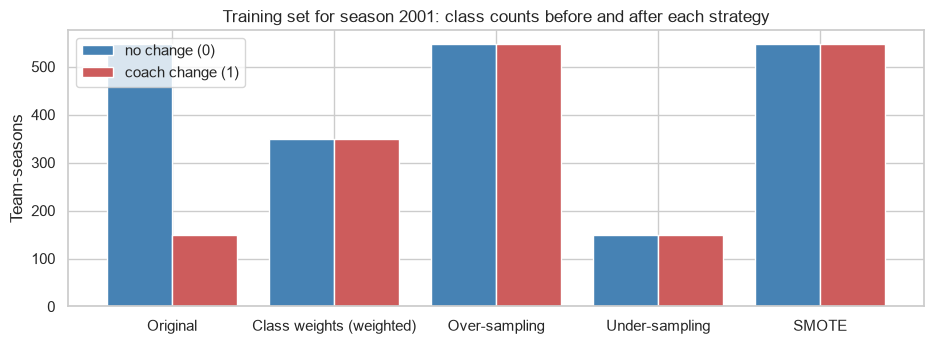

In [5]:
STRATEGIES = ['none', 'class weights', 'over-sampling', 'under-sampling', 'SMOTE']
HAS_CLASS_WEIGHT = ['Logistic regression', 'Decision tree', 'Random forest', 'SVM (RBF)']
configs = {}
for a, model in ALGORITHMS.items():
    for s in STRATEGIES:
        if s != 'class weights' or a in HAS_CLASS_WEIGHT:
            configs[(a, s)] = pipeline(model, s)
strategy_pred = evaluate_many(configs, TUNE)
strategy_table = pd.DataFrame(index=list(ALGORITHMS), columns=STRATEGIES, dtype=float)
for (a, s), pred in strategy_pred.items():
    strategy_table.loc[a, s] = pooled_ap(pred)
best_strategy = strategy_table.idxmax(axis=1)
print('Pooled PR-AUC on the tuning seasons, default parameters:')
display(strategy_table.round(3))
print('Mean over algorithms:', strategy_table.mean().round(3).to_dict())
print('Best strategy per algorithm:', best_strategy.to_dict())

rows = []
for a in ['Logistic regression', 'Random forest']:
    for s in STRATEGIES:
        pred = strategy_pred[(a, s)]
        flag = pred['p'] >= 0.5
        tp = (flag & (pred['y'] == 1)).sum()
        rows.append({'model': a, 'strategy': s, 'flagged at 0.5': flag.mean(), 'recall at 0.5': tp / pred['y'].sum(),
                     'precision at 0.5': tp / flag.sum() if flag.sum() > 0 else 0.0})
display(pd.DataFrame(rows).round(3))

# Class counts of the training set for season 2001 (seasons 1967-2000)
train = d[d['year'] < 2001]
X_train = make_pipeline(IterativeImputer(max_iter=10, random_state=SEED), StandardScaler()).fit_transform(train[FEATURES])
y_train = train[TARGET].values
counts = {'Original': np.bincount(y_train), 'Class weights (weighted)': np.array([len(y_train) / 2, len(y_train) / 2])}
for name, sampler in [('Over-sampling', RandomOverSampler(random_state=SEED)), ('Under-sampling', RandomUnderSampler(random_state=SEED)),
                      ('SMOTE', SMOTE(random_state=SEED))]:
    counts[name] = np.bincount(sampler.fit_resample(X_train, y_train)[1])
print('Class counts (no change, change):', {k: [int(v) for v in c] for k, c in counts.items()})
x = np.arange(len(counts))
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.bar(x - 0.2, [c[0] for c in counts.values()], 0.4, label='no change (0)', color='steelblue')
ax.bar(x + 0.2, [c[1] for c in counts.values()], 0.4, label='coach change (1)', color='indianred')
ax.set_xticks(x, list(counts))
ax.set(title='Training set for season 2001: class counts before and after each strategy', ylabel='Team-seasons')
ax.legend()
plt.tight_layout()
plt.show()

**What we found:** Averaged over the algorithms, no handling ranks the teams best (pooled PR-AUC 0.240), ahead of class weights (0.229), under-sampling (0.227), over-sampling (0.219) and SMOTE (0.218). Single algorithms gain a little: logistic regression with under-sampling (0.237 to 0.262), the tree with class weights (0.195 to 0.222), k-NN with SMOTE (0.260 to 0.272) and the forest with class weights (0.231 to 0.232). Gradient boosting loses with every resampler (0.273 down to about 0.21), and the SVM is best without handling.

The second table shows what resampling really does: without it, logistic regression flags 0.5% of the teams at the usual threshold 0.5 and the forest flags none; with under-sampling they flag 31% and 39%. The class counts for season 2001 show the mechanics: 548 against 150 originally, 548/548 after over-sampling and SMOTE, 150/150 after under-sampling, and 349/349 in weight with class weights.

**Interpretation:** resampling moves the probabilities up, so that 0.5 becomes a usable threshold, but it hardly improves the ranking, which is what PR-AUC measures. A threshold chosen on the tuning seasons (section 6) does the same job without distorting the probabilities. This agrees with the comparison in notebook 1 (3.10.1).

**Decision:** use the best strategy of each algorithm on the tuning seasons: under-sampling for logistic regression, class weights for the tree and the forest, SMOTE for k-NN, and none for naive Bayes, boosting and the SVM. The gains are small, so section 9 checks on the evaluation seasons whether this helped.

## 5. Tuning and the model choice

For every algorithm, a small grid search on the tuning seasons with the strategy chosen in 4.2 and the pooled PR-AUC as score, and we time it. The grids are small on purpose: there are only 500 to 700 training team-seasons per fold and about 37 changes in the tuning seasons, so a large grid would mostly fit noise.

**Rule for the final model.** The tuned algorithm with the best pooled PR-AUC on the tuning seasons; when several are within 0.005 of the best, the one with the best mean PR-AUC per season among them. This is the same kind of tie-break as in notebook 2 (section 7). The evaluation seasons play no part in it.

In [6]:
GRIDS = {
    'Logistic regression': {'C': [0.003, 0.01, 0.03, 0.1, 0.3, 1, 10]},
    'Decision tree': {'max_depth': [2, 3, 4, 6, 8], 'min_samples_leaf': [5, 15, 30]},
    'KNN': {'n_neighbors': [5, 10, 20, 40, 80], 'weights': ['uniform', 'distance']},
    'Naive Bayes': {'var_smoothing': [1e-9, 1e-6, 1e-3, 1e-2, 1e-1, 1]},
    'Random forest': {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 5, 15]},
    'Gradient boosting': {'n_estimators': [50, 100, 200], 'learning_rate': [0.03, 0.1], 'max_depth': [1, 2, 3]},
    'SVM (RBF)': {'C': [0.1, 1, 10], 'gamma': ['scale', 0.003, 0.01, 0.03]},
}
configs = {}
for a in ALGORITHMS:
    for i, params in enumerate(ParameterGrid(GRIDS[a])):
        configs[(a, i)] = pipeline(ALGORITHMS[a], best_strategy[a], params)
start = time.time()
grid_pred = evaluate_many(configs, TUNE)
print(f'Grid search: {len(configs)} configurations x {len(TUNE)} seasons = {len(configs) * len(TUNE)} fits in {time.time() - start:.0f} seconds (parallel)')

best_params, tune_pred, rows = {}, {}, []
for a in ALGORITHMS:
    grid = list(ParameterGrid(GRIDS[a]))
    grid_scores = [pooled_ap(grid_pred[(a, i)]) for i in range(len(grid))]
    best = int(np.argmax(grid_scores))
    best_params[a] = grid[best]
    tune_pred[a] = grid_pred[(a, best)]
    rows.append({'algorithm': a, 'strategy': best_strategy[a], 'grid size': len(grid), 'best parameters': grid[best],
                 'PR-AUC default': strategy_table.loc[a, 'none'], 'PR-AUC with strategy': strategy_table.loc[a, best_strategy[a]],
                 'PR-AUC tuned': grid_scores[best], 'worst grid point': min(grid_scores),
                 'PR-AUC tuned, mean per season': scores(tune_pred[a])['PR-AUC mean']})
tuning = pd.DataFrame(rows).set_index('algorithm')
pd.set_option('display.max_colwidth', 80)
display(tuning.round(3))
FINAL = {a: pipeline(ALGORITHMS[a], best_strategy[a], best_params[a]) for a in ALGORITHMS}

# The rule stated above
best_pooled = tuning['PR-AUC tuned'].max()
close = tuning[tuning['PR-AUC tuned'] >= best_pooled - 0.005]
SELECTED = close['PR-AUC tuned, mean per season'].idxmax()
print('Within 0.005 of the best pooled PR-AUC:', close['PR-AUC tuned'].round(4).to_dict())
print('Selected model:', SELECTED, '| best on pooled PR-AUC alone:', tuning['PR-AUC tuned'].idxmax())

Grid search: 80 configurations x 7 seasons = 560 fits in 22 seconds (parallel)


,strategy,grid size,best parameters,PR-AUC default,PR-AUC with strategy,PR-AUC tuned,worst grid point,"PR-AUC tuned, mean per season"
algorithm,,,,,,,,
Logistic regression,under-sampling,7,{'C': 10},0.237,0.262,0.262,0.237,0.299
Decision tree,class weights,15,"{'max_depth': 4, 'min_samples_leaf': 5}",0.195,0.222,0.295,0.173,0.269
KNN,SMOTE,10,"{'n_neighbors': 5, 'weights': 'distance'}",0.260,0.272,0.293,0.216,0.339
Naive Bayes,none,6,{'var_smoothing': 1},0.200,0.200,0.204,0.200,0.289
Random forest,class weights,12,"{'max_depth': 5, 'min_samples_leaf': 15}",0.231,0.232,0.234,0.214,0.308
Gradient boosting,none,18,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}",0.273,0.273,0.299,0.207,0.374
SVM (RBF),none,12,"{'C': 1, 'gamma': 'scale'}",0.286,0.286,0.286,0.238,0.336


Within 0.005 of the best pooled PR-AUC: {'Decision tree': 0.2953, 'Gradient boosting': 0.2992}
Selected model: Gradient boosting | best on pooled PR-AUC alone: Gradient boosting


**What we found:** After tuning, gradient boosting is best on the tuning seasons (pooled PR-AUC 0.299 with 100 trees of depth 2 and learning rate 0.1), ahead of the decision tree (0.295, depth 4, leaves of 5), k-NN (0.293, 5 neighbours with distance weights) and the SVM (0.286, its default settings). Logistic regression (0.262), the forest (0.234) and naive Bayes (0.204) follow. The models that overfit with their defaults gain most: the tree goes from 0.222 to 0.295 and k-NN from 0.272 to 0.293. The choice of parameters matters a lot for the tree and boosting (worst grid points 0.173 and 0.207) and hardly for naive Bayes. Two best values are at a grid edge: C = 10 for logistic regression (the validation curve in 5.1 shows it is flat from 0.1 on) and var_smoothing = 1 for naive Bayes. The whole grid search (560 fits) takes 22 seconds when run in parallel.

By the rule, the tree (0.2953) and boosting (0.2992) are within 0.005 of each other, and boosting has the far better mean per season (0.374 against 0.269). Boosting is also best on the pooled PR-AUC alone, so in this run the tie-break does not change the choice.

**Decision:** the final model is gradient boosting (100 trees, depth 2, learning rate 0.1, no resampling). These tuning scores are optimistic, because the parameters were chosen on the same seasons; section 7 gives the honest estimate.

### 5.1 Validation curves

For six algorithms, change one parameter while the others stay at their tuned values and plot the training PR-AUC (mean over the folds) next to the validation PR-AUC (pooled over the tuning seasons). k-NN is shown with uniform weights, because with distance weights every training team is its own neighbour and the training score is always 1.

The curves show where each parameter moves a model from underfitting (both curves low) to overfitting (training high, validation falling), and whether the grid was wide enough.

Logistic regression, C | training [0.3, 0.34, 0.36, 0.36, 0.35, 0.35] | validation [0.23, 0.25, 0.26, 0.26, 0.26, 0.26]
Decision tree, max_depth | training [0.25, 0.27, 0.3, 0.34, 0.46, 0.61, 0.84] | validation [0.18, 0.17, 0.25, 0.3, 0.23, 0.21, 0.2]
KNN, n_neighbors | training [0.91, 0.79, 0.6, 0.47, 0.37, 0.34] | validation [0.26, 0.27, 0.26, 0.23, 0.23, 0.22]
Random forest, max_depth | training [0.38, 0.48, 0.58, 0.75, 0.83, 0.84] | validation [0.21, 0.21, 0.21, 0.23, 0.23, 0.22]
Gradient boosting, n_estimators | training [0.51, 0.64, 0.75, 0.88, 0.97, 1.0] | validation [0.25, 0.27, 0.28, 0.3, 0.29, 0.25]
SVM (RBF), C | training [0.94, 0.95, 0.95, 0.97, 0.99, 0.99] | validation [0.29, 0.29, 0.29, 0.28, 0.24, 0.23]


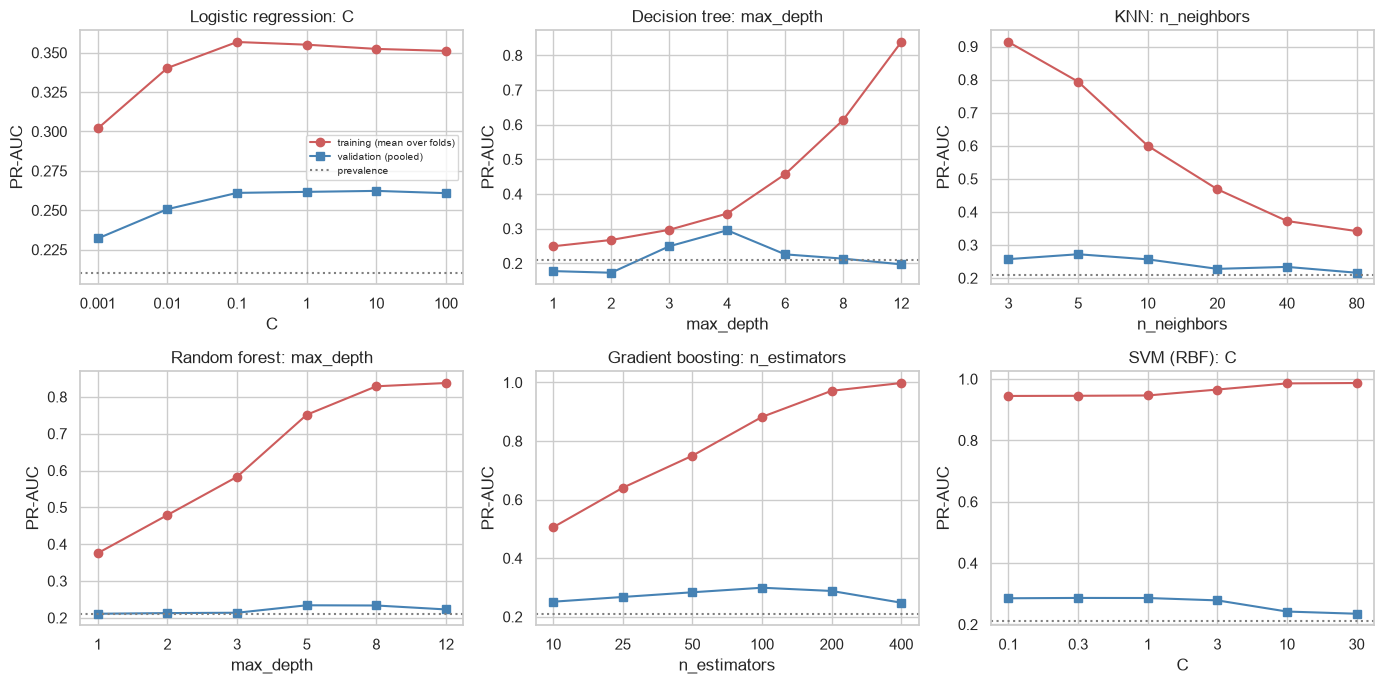

In [7]:
CURVES = [('Logistic regression', 'C', [0.001, 0.01, 0.1, 1, 10, 100]),
          ('Decision tree', 'max_depth', [1, 2, 3, 4, 6, 8, 12]),
          ('KNN', 'n_neighbors', [3, 5, 10, 20, 40, 80]),
          ('Random forest', 'max_depth', [1, 2, 3, 5, 8, 12]),
          ('Gradient boosting', 'n_estimators', [10, 25, 50, 100, 200, 400]),
          ('SVM (RBF)', 'C', [0.1, 0.3, 1, 3, 10, 30])]
configs = {}
for a, param, values in CURVES:
    for v in values:
        params = dict(best_params[a])
        if a == 'KNN':
            params['weights'] = 'uniform'
        params[param] = v
        configs[(a, v)] = pipeline(ALGORITHMS[a], best_strategy[a], params)
curve_pred = evaluate_many(configs, TUNE)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (a, param, values) in zip(axes.ravel(), CURVES):
    train_ap = [curve_pred[(a, v)].groupby('year')['train_ap'].first().mean() for v in values]
    valid_ap = [pooled_ap(curve_pred[(a, v)]) for v in values]
    ax.plot(range(len(values)), train_ap, 'o-', color='indianred', label='training (mean over folds)')
    ax.plot(range(len(values)), valid_ap, 's-', color='steelblue', label='validation (pooled)')
    ax.axhline(known[TARGET].mean(), color='grey', ls=':', label='prevalence')
    ax.set_xticks(range(len(values)), [str(v) for v in values])
    ax.set(title=f'{a}: {param}', xlabel=param, ylabel='PR-AUC')
    print(f'{a}, {param} | training {np.round(train_ap, 2).tolist()} | validation {np.round(valid_ap, 2).tolist()}')
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**What we found** (training PR-AUC against validation PR-AUC):
- **Logistic regression, C:** both curves low and close (0.30-0.36 against 0.23-0.26) and flat from C = 0.1: a high-bias model; more flexibility does not help because the features carry little linear signal.
- **Decision tree, depth:** training rises from 0.25 to 0.84, validation peaks at depth 4 (0.30) and falls to 0.20 at depth 12: deep trees overfit.
- **k-NN, neighbours:** training falls from 0.91 (k = 3) to 0.34 (k = 80), validation is best for small k (0.27 at k = 5) and drifts down to 0.22 as the average moves towards the prevalence.
- **Random forest, depth:** with leaves of at least 15 teams the forest cannot memorise much (training 0.38 to 0.84) and validation stays flat at 0.21-0.23.
- **Gradient boosting, trees:** training rises from 0.51 to 1.00, validation peaks at 100 trees (0.30) and falls to 0.25 at 400: more rounds fit the noise.
- **SVM, C:** training is high everywhere (0.94-0.99), validation 0.29 up to C = 1 and 0.23 at C = 30: a harder margin overfits.

**Interpretation:** no curve goes above about 0.30, only 0.10 above the prevalence (0.19). The signal is weak, and every model does best at moderate complexity.

## 6. Threshold selection

PR-AUC only ranks the teams; to flag teams we need a threshold on the predicted probability. For each tuned model (and for the two baselines that rank teams) we take the predictions on the tuning seasons and choose the threshold with the best F1, both without a limit and with at most 40% of the teams flagged. We also plot the precision-recall curves.

F1 balances missed changes against false alarms, which both matter for a watch list. With a weak signal the best F1 without a limit can mean "flag almost everybody" (at a prevalence of 0.19 that already gives an F1 of about 0.32), which is useless, hence the limit. The threshold is part of the model, so it is chosen on the tuning seasons only.

,model,rule,threshold,flagged,precision,recall,F1
0,Logistic regression,best F1,0.396,0.472,0.242,0.595,0.344
1,Logistic regression,"best F1, at most 40% flagged",0.471,0.373,0.250,0.486,0.330
2,Decision tree,best F1,0.496,0.560,0.222,0.649,0.331
3,Decision tree,"best F1, at most 40% flagged",0.684,0.130,0.400,0.270,0.323
4,KNN,best F1,0.809,0.140,0.444,0.324,0.375
5,KNN,"best F1, at most 40% flagged",0.809,0.140,0.444,0.324,0.375
6,Naive Bayes,best F1,0.177,0.596,0.217,0.676,0.329
7,Naive Bayes,"best F1, at most 40% flagged",0.333,0.399,0.208,0.432,0.281
8,Random forest,best F1,0.261,0.948,0.197,0.973,0.327
9,Random forest,"best F1, at most 40% flagged",0.564,0.130,0.360,0.243,0.290


Thresholds: {'Majority (no change)': 0.5, 'Constant prevalence': 0.5, 'Stratified random': 0.5, 'Rule: low last-season points': -0.939, 'Logistic: last-season points': 0.224, 'Logistic regression': 0.471, 'Decision tree': 0.684, 'KNN': 0.809, 'Naive Bayes': 0.333, 'Random forest': 0.564, 'Gradient boosting': 0.237, 'SVM (RBF)': 0.22}


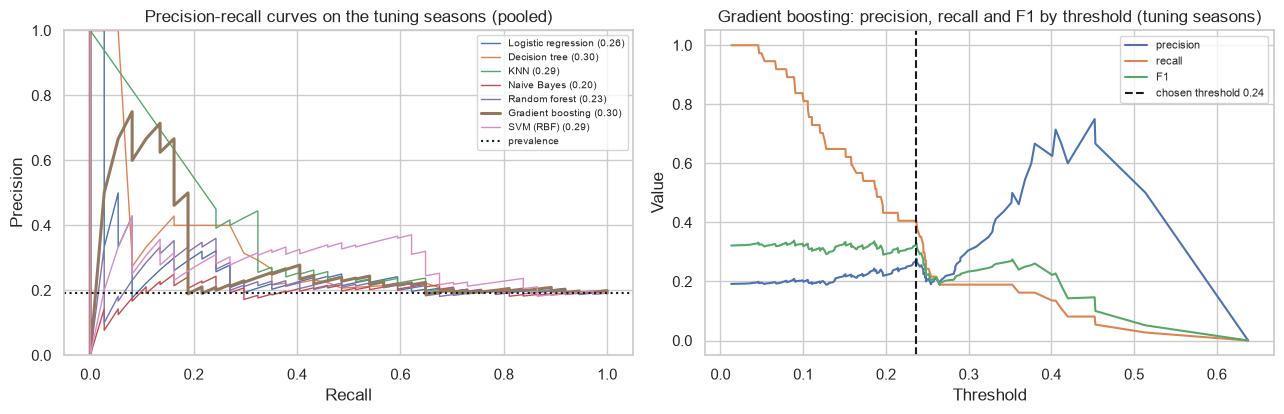

In [8]:
def pick_threshold(pred, max_flagged=None):
    # Threshold with the best F1 (optionally flagging at most a given share of the teams)
    best, best_f1 = None, -1.0
    for t in np.unique(pred['p']):
        flag = pred['p'] >= t
        if max_flagged is not None and flag.mean() > max_flagged:
            continue
        tp = (flag & (pred['y'] == 1)).sum()
        if tp == 0:
            continue
        precision, recall = tp / flag.sum(), tp / pred['y'].sum()
        f1 = 2 * precision * recall / (precision + recall)
        if f1 > best_f1:
            best, best_f1 = t, f1
    return best


CAP = 0.4
rows = []
for a in ALGORITHMS:
    for label, cap in [('best F1', None), ('best F1, at most 40% flagged', CAP)]:
        s = scores(tune_pred[a], pick_threshold(tune_pred[a], cap))
        rows.append({'model': a, 'rule': label, 'threshold': s['threshold'], 'flagged': s['flagged'],
                     'precision': s['precision'], 'recall': s['recall'], 'F1': s['F1']})
display(pd.DataFrame(rows).round(3))

# Thresholds used from now on: capped rule, tuning seasons only (0.5 for the baselines without a ranking)
THRESHOLD = {b: 0.5 for b in BASELINES}
for b in ['Rule: low last-season points', 'Logistic: last-season points']:
    THRESHOLD[b] = pick_threshold(base_tune[b], CAP)
for a in ALGORITHMS:
    THRESHOLD[a] = pick_threshold(tune_pred[a], CAP)
print('Thresholds:', {k: round(float(v), 3) for k, v in THRESHOLD.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for a in ALGORITHMS:
    P, R, _ = precision_recall_curve(tune_pred[a]['y'], tune_pred[a]['p'])
    axes[0].plot(R, P, lw=2.2 if a == SELECTED else 1, label=f'{a} ({pooled_ap(tune_pred[a]):.2f})')
axes[0].axhline(tune_pred[SELECTED]['y'].mean(), color='k', ls=':', label='prevalence')
axes[0].set(title='Precision-recall curves on the tuning seasons (pooled)', xlabel='Recall', ylabel='Precision', ylim=(0, 1))
axes[0].legend(fontsize=7)
P, R, T = precision_recall_curve(tune_pred[SELECTED]['y'], tune_pred[SELECTED]['p'])
axes[1].plot(T, P[:-1], label='precision')
axes[1].plot(T, R[:-1], label='recall')
axes[1].plot(T, 2 * P[:-1] * R[:-1] / np.maximum(P[:-1] + R[:-1], 1e-12), label='F1')
axes[1].axvline(THRESHOLD[SELECTED], color='k', ls='--', label=f'chosen threshold {THRESHOLD[SELECTED]:.2f}')
axes[1].set(title=f'{SELECTED}: precision, recall and F1 by threshold (tuning seasons)', xlabel='Threshold', ylabel='Value')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**What we found:** Without a limit, the best-F1 threshold often flags most teams: 94.8% for the random forest, 81.9% for gradient boosting (recall 0.892, precision 0.209), 59.6% for naive Bayes and 56.0% for the tree. That is hardly better than "flag everybody". With the 40% limit the thresholds become useful: gradient boosting at 0.237 flags 28.0% of the teams with precision 0.278 and recall 0.405 (F1 0.330); logistic regression flags 37.3%, the forest and the tree 13.0%. For the SVM (32.1% flagged, F1 0.465) and k-NN (14.0%) the limit is not active. The one-feature baseline gets the threshold 0.224 by the same rule.

**Interpretation:** the high tuning F1 of the SVM is optimistic, because it was tuned on these same seasons. The right plot shows that for boosting F1 stays at about 0.3 for every threshold up to the chosen 0.24 and drops quickly above it, while recall falls below 0.2: the threshold sits at the end of the flat part, and a slightly higher one would lose most of the changes. The left plot shows that all models are clearly above the prevalence only for the first fifth of the recall, the few highest-ranked teams.

**Decision:** for every model, the threshold with the best F1 among those that flag at most 40% of the teams, chosen on the tuning seasons.

## 7. Comparison on the evaluation seasons 2002-2008

Run every tuned model and every baseline on the six evaluation seasons with all choices frozen (strategy, parameters, threshold) and report all metrics, including the G2 check.

These seasons were not used for any choice, so they estimate how the models would do on future seasons.

In [9]:
eval_pred = evaluate_many(FINAL, EVAL)
all_eval = dict(base_eval)
all_eval.update(eval_pred)
evaluation = pd.DataFrame({name: scores(pred, THRESHOLD[name]) for name, pred in all_eval.items()}).T.astype(float)
show = evaluation[['PR-AUC pooled', 'ROC-AUC', 'Brier', 'precision', 'recall', 'F1', 'P@k', 'top-quarter share']].round(3)
show.insert(1, 'PR-AUC mean ± sd', [f"{m:.3f} ± {s:.3f}" for m, s in zip(evaluation['PR-AUC mean'], evaluation['PR-AUC sd'])])
display(show)
prevalence = eval_pred[SELECTED]['y'].mean()
print(f"Evaluation seasons: {len(eval_pred[SELECTED])} team-seasons, {int(eval_pred[SELECTED]['y'].sum())} changes, prevalence {prevalence:.3f}")
g2_ap, g2_quarter = evaluation.loc[SELECTED, 'PR-AUC pooled'], evaluation.loc[SELECTED, 'top-quarter share']
print(f"G2 check for {SELECTED}: PR-AUC {g2_ap:.3f} vs 1.25 x prevalence = {1.25 * prevalence:.3f}; "
      f"top-quarter share {g2_quarter:.3f} vs 0.40")

,PR-AUC pooled,PR-AUC mean ± sd,ROC-AUC,Brier,precision,recall,F1,P@k,top-quarter share
Majority (no change),0.200,0.200 ± 0.052,0.500,0.200,0.000,0.000,0.000,0.200,0.267
Constant prevalence,0.195,0.200 ± 0.052,0.488,0.160,0.000,0.000,0.000,0.200,0.267
Stratified random,0.207,0.222 ± 0.057,0.521,0.367,0.222,0.333,0.267,0.222,0.296
Rule: low last-season points,0.324,0.392 ± 0.151,0.592,NaN,0.250,0.306,0.275,0.306,0.306
Logistic: last-season points,0.310,0.392 ± 0.151,0.589,0.157,0.244,0.306,0.272,0.306,0.306
Logistic regression,0.274,0.346 ± 0.085,0.602,0.225,0.260,0.528,0.349,0.306,0.389
Decision tree,0.266,0.314 ± 0.114,0.602,0.237,0.304,0.194,0.237,0.294,0.383
KNN,0.236,0.317 ± 0.124,0.558,0.298,0.333,0.194,0.246,0.194,0.250
Naive Bayes,0.283,0.334 ± 0.123,0.580,0.172,0.308,0.444,0.364,0.278,0.417
Random forest,0.301,0.375 ± 0.115,0.621,0.216,0.400,0.222,0.286,0.361,0.361


Evaluation seasons: 180 team-seasons, 36 changes, prevalence 0.200
G2 check for Gradient boosting: PR-AUC 0.331 vs 1.25 x prevalence = 0.250; top-quarter share 0.417 vs 0.40


**What we found** (180 team-seasons, 36 changes, prevalence 0.200): gradient boosting has the best pooled PR-AUC (0.331) and the best mean per season (0.407 ± 0.158), ahead of the rule (0.324), the one-feature baseline (0.310) and the random forest (0.301); the SVM (0.288), naive Bayes (0.283), logistic regression (0.274), the tree (0.266) and k-NN (0.236) are below the baseline. Boosting also leads on ROC-AUC (0.634), F1 (0.381 at its threshold: precision 0.333, recall 0.444) and precision@k (0.361, with the forest), and its Brier score (0.154) is the best of all, below the constant prevalence (0.160). The models trained with resampling have much worse Brier scores (logistic regression 0.225, k-NN 0.298), because their probabilities are shifted up.

**G2 check:** boosting's PR-AUC is 0.331 against the required 1.25 x 0.200 = 0.250, and its riskiest quarter of teams holds 41.7% of the real changes (15 of 36) against the required 40%. The baseline reaches 30.6%.

**Interpretation:** G2 is met, but the second part only just: one change fewer in the riskiest quarter would miss it. The gain over the one-feature baseline is small (0.02 PR-AUC); section 7.2 tests whether it is real.

### 7.1 Curves, confusion matrix and calibration

Precision-recall and ROC curves of the models and the two ranking baselines on the evaluation seasons, the confusion matrix of the selected model at its threshold, and a calibration plot (five equal-size groups of predicted risk, mean predicted probability against the observed share of changes).

The curves show where in the ranking a model is better; the calibration plot shows whether a predicted 30% really means about 30%.

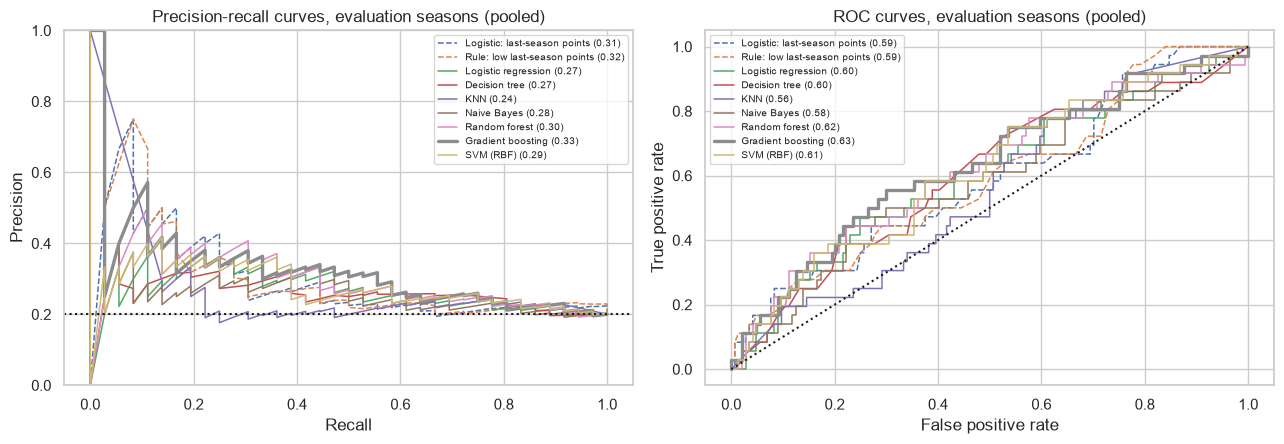

Gradient boosting: mean predicted per group [0.09, 0.13, 0.18, 0.23, 0.36], observed [0.08, 0.17, 0.17, 0.25, 0.33]
Logistic regression: mean predicted per group [0.18, 0.32, 0.42, 0.54, 0.69], observed [0.14, 0.17, 0.17, 0.19, 0.33]


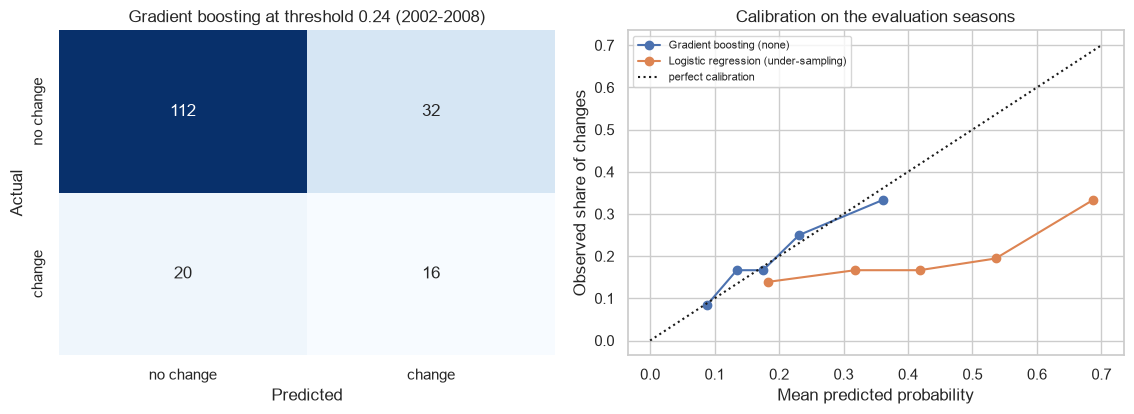

Confusion matrix [[TN, FP], [FN, TP]]: [[112, 32], [20, 16]]


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name in ['Logistic: last-season points', 'Rule: low last-season points'] + list(ALGORITHMS):
    pred = all_eval[name]
    P, R, _ = precision_recall_curve(pred['y'], pred['p'])
    fpr, tpr, _ = roc_curve(pred['y'], pred['p'])
    style = dict(lw=2.4 if name == SELECTED else 1.1, ls='--' if name in BASELINES else '-')
    axes[0].plot(R, P, label=f'{name} ({pooled_ap(pred):.2f})', **style)
    axes[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(pred['y'], pred['p']):.2f})", **style)
axes[0].axhline(prevalence, color='k', ls=':')
axes[1].plot([0, 1], [0, 1], 'k:')
axes[0].set(title='Precision-recall curves, evaluation seasons (pooled)', xlabel='Recall', ylabel='Precision', ylim=(0, 1))
axes[1].set(title='ROC curves, evaluation seasons (pooled)', xlabel='False positive rate', ylabel='True positive rate')
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

pred = eval_pred[SELECTED]
cm = confusion_matrix(pred['y'], (pred['p'] >= THRESHOLD[SELECTED]).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0], xticklabels=['no change', 'change'], yticklabels=['no change', 'change'])
axes[0].set(title=f'{SELECTED} at threshold {THRESHOLD[SELECTED]:.2f} (2002-2008)', xlabel='Predicted', ylabel='Actual')
for name in [SELECTED, 'Logistic regression']:
    p = eval_pred[name]
    group = pd.qcut(p['p'].rank(method='first'), 5, labels=False)
    calib = p.groupby(group).agg(predicted=('p', 'mean'), observed=('y', 'mean'))
    axes[1].plot(calib['predicted'], calib['observed'], 'o-', label=f'{name} ({best_strategy[name]})')
    print(f'{name}: mean predicted per group {calib["predicted"].round(2).tolist()}, observed {calib["observed"].round(2).tolist()}')
axes[1].plot([0, 0.7], [0, 0.7], 'k:', label='perfect calibration')
axes[1].set(title='Calibration on the evaluation seasons', xlabel='Mean predicted probability', ylabel='Observed share of changes')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Confusion matrix [[TN, FP], [FN, TP]]:', cm.tolist())

**What we found:** The ROC curves of all models stay close to the diagonal (AUC 0.56 to 0.63). The confusion matrix of boosting at its threshold is [[112, 32], [20, 16]]: it finds 16 of the 36 changes (recall 0.444) with 32 false alarms (precision 16/48 = 0.333). The boosting probabilities are well calibrated: in five groups of rising predicted risk the mean prediction goes from 0.09 to 0.36 and the observed change rate from 0.08 to 0.33. Logistic regression trained with under-sampling predicts 0.18 to 0.69 for observed rates of 0.14 to 0.33.

**Interpretation:** resampling distorts the probabilities, as notebook 1 found; boosting without resampling gives usable ones. Even its highest-risk group has a mean prediction of only 0.36, so boosting cannot single out a team as almost certain to change coach: the information in the features is limited.

### 7.2 Significance tests

Three tests, because six seasons are very few: the **Friedman test** (do the methods differ at all across the seasons?), the **Wilcoxon signed-rank test** of each model against the one-feature logistic baseline on the six seasonal PR-AUC values (with six seasons the smallest possible p-value is 0.031), and a **paired bootstrap** of the pooled PR-AUC difference, resampling the 180 team-seasons 2,000 times (more power, but it ignores the variation between seasons). The bootstrap is also run against the constant prevalence, to see which models beat chance.

In [11]:
methods = ['Logistic: last-season points', 'Rule: low last-season points'] + list(ALGORITHMS)
season_ap = pd.DataFrame({m: all_eval[m].groupby('year').apply(pooled_ap) for m in methods})
print('PR-AUC per evaluation season')
display(season_ap.round(3))
friedman = stats.friedmanchisquare(*[season_ap[m] for m in methods])
print(f'Friedman test, {len(season_ap)} seasons and {len(methods)} methods: chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.3f}')
print('Mean rank per season (1 = best):', season_ap.rank(axis=1, ascending=False).mean().round(2).to_dict())

# Paired bootstrap: the same resampled team-seasons for every method
BASE = 'Logistic: last-season points'
for m in methods:
    assert all_eval[m].index.equals(all_eval[BASE].index)
y = all_eval[BASE]['y'].values
rng = np.random.default_rng(SEED)
samples = [rng.integers(0, len(y), len(y)) for _ in range(2000)]


def boot_ap(name):
    p = all_eval[name]['p'].values
    return np.array([average_precision_score(y[i], p[i]) for i in samples])


boot_base, boot_prior = boot_ap(BASE), boot_ap('Constant prevalence')
rows = []
for m in list(ALGORITHMS) + ['Rule: low last-season points']:
    boot_m = boot_ap(m)
    diff = boot_m - boot_base
    rows.append({'model': m, 'pooled PR-AUC diff vs baseline': pooled_ap(all_eval[m]) - pooled_ap(all_eval[BASE]),
                 'seasons better (of 6)': int((season_ap[m] > season_ap[BASE]).sum()),
                 'Wilcoxon p': stats.wilcoxon(season_ap[m], season_ap[BASE]).pvalue,
                 'bootstrap CI low': np.percentile(diff, 2.5), 'bootstrap CI high': np.percentile(diff, 97.5),
                 'P(no better than baseline)': (diff <= 0).mean(),
                 'P(no better than chance)': ((boot_m - boot_prior) <= 0).mean()})
display(pd.DataFrame(rows).set_index('model').round(3))

PR-AUC per evaluation season


,Logistic: last-season points,Rule: low last-season points,Logistic regression,Decision tree,KNN,Naive Bayes,Random forest,Gradient boosting,SVM (RBF)
year,,,,,,,,,
2002,0.489,0.489,0.417,0.282,0.320,0.505,0.475,0.252,0.533
2003,0.546,0.546,0.438,0.248,0.277,0.396,0.545,0.687,0.586
2005,0.362,0.362,0.248,0.223,0.541,0.374,0.284,0.420,0.373
2006,0.520,0.520,0.250,0.536,0.184,0.329,0.288,0.302,0.170
2007,0.181,0.181,0.400,0.273,0.237,0.150,0.270,0.316,0.224
2008,0.252,0.252,0.325,0.322,0.341,0.251,0.391,0.466,0.321


Friedman test, 6 seasons and 9 methods: chi2 = 3.45, p = 0.903
Mean rank per season (1 = best): {'Logistic: last-season points': 5.0, 'Rule: low last-season points': 5.0, 'Logistic regression': 5.33, 'Decision tree': 5.83, 'KNN': 5.33, 'Naive Bayes': 5.67, 'Random forest': 4.83, 'Gradient boosting': 3.33, 'SVM (RBF)': 4.67}


,pooled PR-AUC diff vs baseline,seasons better (of 6),Wilcoxon p,bootstrap CI low,bootstrap CI high,P(no better than baseline),P(no better than chance)
model,,,,,,,
Logistic regression,-0.036,2,0.562,-0.169,0.093,0.710,0.028
Decision tree,-0.044,3,0.438,-0.173,0.086,0.756,0.039
KNN,-0.075,3,0.562,-0.219,0.034,0.894,0.140
Naive Bayes,-0.027,2,0.312,-0.119,0.047,0.780,0.027
Random forest,-0.009,2,0.844,-0.132,0.118,0.558,0.008
Gradient boosting,0.021,4,1.000,-0.129,0.158,0.408,0.005
SVM (RBF),-0.022,5,0.438,-0.152,0.105,0.628,0.010
Rule: low last-season points,0.014,0,1.000,-0.026,0.040,0.382,0.009


**What we found:** The PR-AUC per season varies a lot (the baseline from 0.181 in 2007 to 0.546 in 2003) and no method wins every season. The Friedman test finds no difference between the nine methods (chi-square 3.45, p = 0.90), although boosting has the best mean rank (3.33). Against the one-feature baseline, every Wilcoxon p-value is 0.31 or higher: boosting is better in 4 of the 6 seasons (p = 1.00) and the SVM in 5 (p = 0.44). The paired bootstrap gives boosting +0.021 PR-AUC, with a 95% interval from -0.129 to +0.158 and a 41% chance of being no better than the baseline; every other model has a negative difference. Against chance (constant prevalence) the picture is clearer: six of the seven models are better with a bootstrap probability above 96% (boosting 99.5%), k-NN is not (86%).

**Interpretation:** the models clearly beat chance, but none is shown to beat "last season's points". With 36 changes and six seasons this sample cannot separate a gain of 0.02.

**Decision:** keep gradient boosting, chosen on the tuning seasons, and describe its gain over the baseline as not proven.

## 8. Overfitting analysis

For every tuned model, compare the PR-AUC on its own training rows with the PR-AUC on the evaluation season it predicts (both averaged over the six evaluation folds).

A large gap means the model memorises its training data. Whether that hurts shows in the evaluation score, not in the gap alone.

,training PR-AUC,evaluation PR-AUC (mean per season),gap
Logistic regression,0.340,0.346,-0.006
Decision tree,0.397,0.314,0.083
KNN,0.999,0.317,0.683
Naive Bayes,0.318,0.334,-0.017
Random forest,0.727,0.375,0.352
Gradient boosting,0.811,0.407,0.404
SVM (RBF),0.928,0.368,0.560


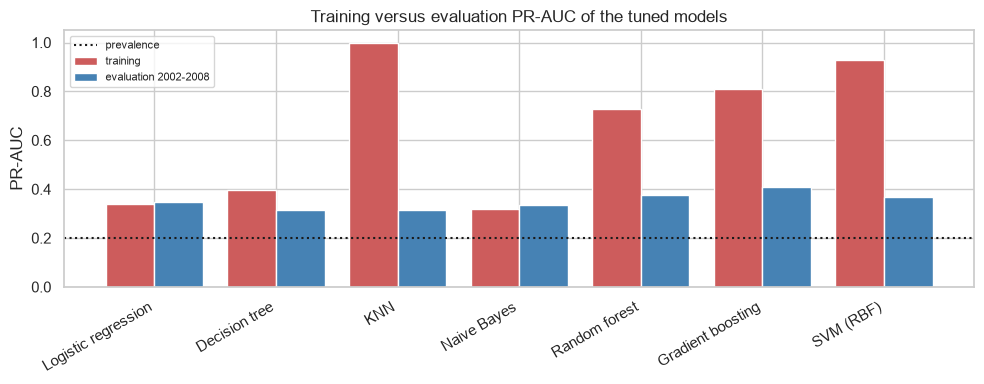

In [12]:
gap = pd.DataFrame({'training PR-AUC': {a: eval_pred[a].groupby('year')['train_ap'].first().mean() for a in ALGORITHMS},
                    'evaluation PR-AUC (mean per season)': {a: scores(eval_pred[a])['PR-AUC mean'] for a in ALGORITHMS}})
gap['gap'] = gap['training PR-AUC'] - gap['evaluation PR-AUC (mean per season)']
display(gap.round(3))
x = np.arange(len(gap))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, gap['training PR-AUC'], 0.4, label='training', color='indianred')
ax.bar(x + 0.2, gap['evaluation PR-AUC (mean per season)'], 0.4, label='evaluation 2002-2008', color='steelblue')
ax.axhline(prevalence, color='k', ls=':', label='prevalence')
ax.set_xticks(x, gap.index, rotation=30, ha='right')
ax.set(title='Training versus evaluation PR-AUC of the tuned models', ylabel='PR-AUC')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What we found:** Logistic regression (training 0.340, evaluation 0.346) and naive Bayes (0.318 against 0.334) do not overfit at all; the tree overfits a little (0.397 against 0.314). Boosting (0.811 against 0.407), the forest (0.727 against 0.375), the SVM (0.928 against 0.368) and k-NN (0.999 against 0.317) fit their training rows much better than new seasons.

**Interpretation:** the two simple models are limited by their bias, not by overfitting. The memorising models still evaluate as well as or better than the simple ones: for boosting the large gap is mostly harmless variance kept in check by its small trees and learning rate. A large gap alone does not identify a bad model; the evaluation score does.

### 8.1 Learning curve

For the selected model, use a random 20%, 40%, ..., 100% of the training rows of each evaluation fold (3 repeats) and record the training and validation PR-AUC.

If the two curves are still far apart and the validation score still rises, more data would help; if they have met and are flat, the model has reached what the features allow.

,train,train_sd,validation,validation_sd
fraction,,,,
0.2,0.999,0.001,0.244,0.039
0.4,0.977,0.002,0.260,0.052
0.6,0.929,0.001,0.267,0.041
0.8,0.872,0.004,0.308,0.040
1.0,0.811,0.000,0.337,0.004


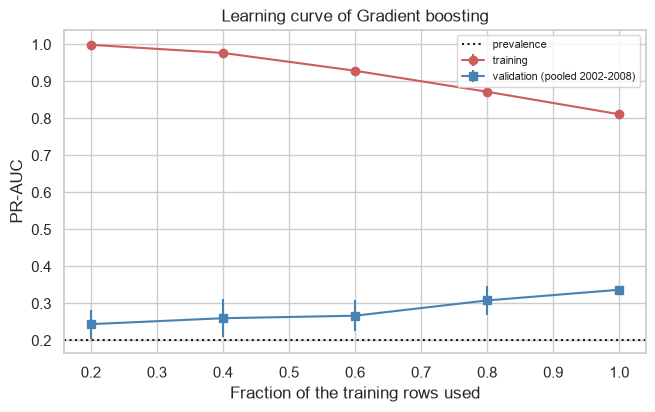

In [13]:
rows = []
for fraction in [0.2, 0.4, 0.6, 0.8, 1.0]:
    for repeat in range(3):
        rng = np.random.default_rng(SEED + repeat)
        train_ap, preds, truth = [], [], []
        for s in EVAL:
            train, test = d[d['year'] < s], d[d['year'] == s]
            sample = train.loc[rng.choice(train.index, size=int(fraction * len(train)), replace=False)]
            fitted = clone(FINAL[SELECTED]).fit(sample[FEATURES], sample[TARGET])
            train_ap.append(average_precision_score(sample[TARGET], fitted.predict_proba(sample[FEATURES])[:, 1]))
            preds.append(fitted.predict_proba(test[FEATURES])[:, 1])
            truth.append(test[TARGET].values)
        rows.append({'fraction': fraction, 'repeat': repeat, 'train': np.mean(train_ap),
                     'validation': average_precision_score(np.concatenate(truth), np.concatenate(preds))})
learning = pd.DataFrame(rows).groupby('fraction').agg(train=('train', 'mean'), train_sd=('train', 'std'),
                                                       validation=('validation', 'mean'), validation_sd=('validation', 'std'))
display(learning.round(3))
plt.figure(figsize=(7.5, 4.2))
plt.errorbar(learning.index, learning['train'], learning['train_sd'], fmt='o-', color='indianred', label='training')
plt.errorbar(learning.index, learning['validation'], learning['validation_sd'], fmt='s-', color='steelblue', label='validation (pooled 2002-2008)')
plt.axhline(prevalence, color='k', ls=':', label='prevalence')
plt.xlabel('Fraction of the training rows used')
plt.ylabel('PR-AUC')
plt.title(f'Learning curve of {SELECTED}')
plt.legend(fontsize=8)
plt.show()

**What we found:** With 20% of the training rows boosting memorises them (training PR-AUC 0.999) and reaches 0.244 on the evaluation seasons. With more rows the training score falls (0.811 with all rows) and the validation score rises: 0.260, 0.267, 0.308 and 0.337 with all rows.

**Interpretation:** the curves are still far apart and the validation score is still rising at 100%, so more seasons would probably still help. A season adds only about 30 team-seasons and 6 changes, which is why the signal is so hard to learn.

## 9. Model improvement

Follow the improvement path of every algorithm and record each step: (1) default parameters, no imbalance handling; (2) the strategy of 4.2; (3) the tuned parameters of section 5; (4) the threshold of section 6 instead of 0.5. Steps 1-3 were chosen on the tuning seasons; the evaluation seasons show whether each gain is real, without any further choice.

The goal set by the baselines: a pooled PR-AUC above the one-feature logistic baseline and a precision@k clearly above the prevalence. Each step answers a weakness seen before: the defaults of trees and k-NN overfit (hence tuning), and the probabilities are too low for the default threshold 0.5 (hence the chosen threshold).

In [14]:
default_eval = evaluate_many({a: pipeline(m) for a, m in ALGORITHMS.items()}, EVAL)
strategy_eval = evaluate_many({a: pipeline(m, best_strategy[a]) for a, m in ALGORITHMS.items()}, EVAL)
steps = pd.DataFrame({
    'tuning: 1 default': {a: pooled_ap(default_tune[a]) for a in ALGORITHMS},
    'tuning: 2 + strategy': {a: strategy_table.loc[a, best_strategy[a]] for a in ALGORITHMS},
    'tuning: 3 + tuned': {a: pooled_ap(tune_pred[a]) for a in ALGORITHMS},
    'evaluation: 1 default': {a: pooled_ap(default_eval[a]) for a in ALGORITHMS},
    'evaluation: 2 + strategy': {a: pooled_ap(strategy_eval[a]) for a in ALGORITHMS},
    'evaluation: 3 + tuned': {a: pooled_ap(eval_pred[a]) for a in ALGORITHMS},
})
display(steps.round(3))
rows = []
for a in ALGORITHMS:
    s = scores(eval_pred[a], THRESHOLD[a])
    rows.append({'model': a, 'F1 at 0.5': scores(eval_pred[a], 0.5)['F1'], 'F1 at chosen threshold': s['F1'],
                 'precision': s['precision'], 'recall': s['recall'], 'P@k': s['P@k']})
display(pd.DataFrame(rows).set_index('model').round(3))
print(f"Goal: baseline pooled PR-AUC {pooled_ap(base_eval[BASE]):.3f} and P@k {evaluation.loc[BASE, 'P@k']:.3f}; prevalence {prevalence:.3f}")

,tuning: 1 default,tuning: 2 + strategy,tuning: 3 + tuned,evaluation: 1 default,evaluation: 2 + strategy,evaluation: 3 + tuned
Logistic regression,0.237,0.262,0.262,0.315,0.272,0.274
Decision tree,0.195,0.222,0.295,0.236,0.251,0.266
KNN,0.260,0.272,0.293,0.225,0.230,0.236
Naive Bayes,0.200,0.200,0.204,0.250,0.250,0.283
Random forest,0.231,0.232,0.234,0.284,0.290,0.301
Gradient boosting,0.273,0.273,0.299,0.239,0.239,0.331
SVM (RBF),0.286,0.286,0.286,0.288,0.288,0.288


,F1 at 0.5,F1 at chosen threshold,precision,recall,P@k
model,,,,,
Logistic regression,0.346,0.349,0.260,0.528,0.306
Decision tree,0.333,0.237,0.304,0.194,0.294
KNN,0.286,0.246,0.333,0.194,0.194
Naive Bayes,0.125,0.364,0.308,0.444,0.278
Random forest,0.372,0.286,0.400,0.222,0.361
Gradient boosting,0.053,0.381,0.333,0.444,0.361
SVM (RBF),0.000,0.308,0.255,0.389,0.333


Goal: baseline pooled PR-AUC 0.310 and P@k 0.306; prevalence 0.200


**What we found:** On the tuning seasons each step helps or is neutral by construction. On the evaluation seasons, which played no part in the choices, the path of boosting is confirmed most clearly: 0.239 with defaults, 0.239 without resampling, 0.331 after tuning (+0.092). The tuning gains also hold for the tree (0.236 to 0.266), naive Bayes (0.250 to 0.283), the forest (0.284 to 0.301) and k-NN (0.225 to 0.236). They do not hold for logistic regression: under-sampling, which helped on the tuning seasons, lowers it from 0.315 to 0.272.

The threshold matters most for models with low probabilities: F1 goes from 0.053 at 0.5 to 0.381 at the chosen threshold for boosting, from 0 to 0.308 for the SVM and from 0.125 to 0.364 for naive Bayes. For the models trained with resampling or class weights the default 0.5 already works, and the chosen threshold is not better (forest 0.372 against 0.286, tree 0.333 against 0.237).

**Interpretation:** picking the best of many options on 193 tuning team-seasons partly fits noise, which is the honest cost of tuning with so few positives. Against the goal, boosting ends 0.021 above the baseline in pooled PR-AUC (0.331 against 0.310) and 0.055 above in precision@k (0.361 against 0.306): better, but not significantly (section 7.2).

## 10. Feature importance

(a) **Permutation importance** of the selected model on the evaluation seasons: shuffle one feature at a time inside each season, predict again and measure the drop in pooled PR-AUC (5 repeats). (b) **Odds ratios** of a logistic regression with the tuned C on the standardised features of 1967-2008, with bootstrap 95% intervals (300 resamples).

Permutation importance works for any model and measures what the predictions depend on in unseen seasons. Odds ratios give the direction: above 1 means that one standard deviation more of the feature raises the odds of a coach change. Features are z-scores inside the season, so "+1 SD" means one standard deviation above the league that season.

Pooled PR-AUC of Gradient boosting on the evaluation seasons: 0.331


,mean drop,sd
feature,,
prev_ga_pg_z,0.0754,0.0174
coach_tenure,0.0453,0.0136
prev_pk_pct_z,0.0367,0.0213
prev_home_edge_z,0.0243,0.0091
coach_new,0.0183,0.0073
prev_luck_z,0.0154,0.0033
prev_save_pct_z,0.0139,0.0165
prev_players_used_z,0.0134,0.0202
prev_gf_pg_z,0.0104,0.0022


Odds ratios whose 95% interval excludes 1:


,odds ratio,low 95%,high 95%,interval excludes 1
prev_playoff_series_won_z,0.770,0.596,0.950,True
prev_coach_change,0.817,0.663,0.986,True
prev_players_used_z,1.265,1.065,1.554,True
prev_goalie_data_missing,1.273,1.072,1.501,True
prev_pp_pct_z,1.290,1.026,1.628,True


Selected hockey features:


,odds ratio,low 95%,high 95%,interval excludes 1
prev_ga_pg_z,1.495,0.981,2.177,False
prev_gf_pg_z,1.268,0.872,1.932,False
prev_luck_z,1.056,0.876,1.285,False
prev_made_playoffs,0.986,0.777,1.237,False
coach_tenure,1.044,0.785,1.310,False
coach_new,0.819,0.610,1.085,False
coach_career_pct,0.805,0.602,1.071,False


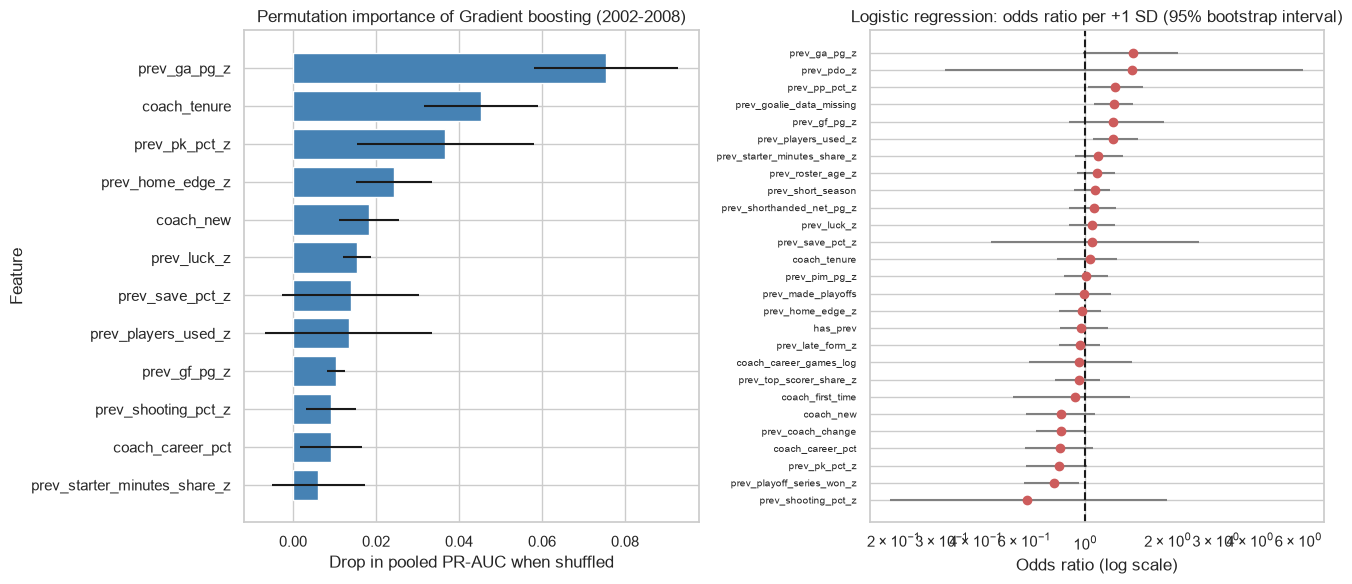

In [15]:
fitted = {s: clone(FINAL[SELECTED]).fit(d.loc[d['year'] < s, FEATURES], d.loc[d['year'] < s, TARGET]) for s in EVAL}
test_X = {s: d.loc[d['year'] == s, FEATURES] for s in EVAL}
y_eval = np.concatenate([d.loc[d['year'] == s, TARGET].values for s in EVAL])
base_ap = average_precision_score(y_eval, np.concatenate([fitted[s].predict_proba(test_X[s])[:, 1] for s in EVAL]))
rows = []
for f in FEATURES:
    drops = []
    for repeat in range(5):
        rng = np.random.default_rng(SEED + repeat)
        p = []
        for s in EVAL:
            X = test_X[s].copy()
            X[f] = rng.permutation(X[f].values)
            p.append(fitted[s].predict_proba(X)[:, 1])
        drops.append(base_ap - average_precision_score(y_eval, np.concatenate(p)))
    rows.append({'feature': f, 'mean drop': np.mean(drops), 'sd': np.std(drops)})
perm = pd.DataFrame(rows).set_index('feature').sort_values('mean drop', ascending=False)
print(f'Pooled PR-AUC of {SELECTED} on the evaluation seasons: {base_ap:.3f}')
display(perm.head(10).round(4))

# Odds ratios of a logistic regression on all seasons 1967-2008, with bootstrap intervals
X_known = make_pipeline(IterativeImputer(max_iter=10, random_state=SEED), StandardScaler()).fit_transform(known[FEATURES])
y_known = known[TARGET].values
C = best_params['Logistic regression']['C']
coef = LogisticRegression(C=C, max_iter=2000).fit(X_known, y_known).coef_[0]
rng = np.random.default_rng(SEED)
boot = []
for _ in range(300):
    i = rng.integers(0, len(y_known), len(y_known))
    boot.append(LogisticRegression(C=C, max_iter=2000).fit(X_known[i], y_known[i]).coef_[0])
boot = np.array(boot)
odds = pd.DataFrame({'odds ratio': np.exp(coef), 'low 95%': np.exp(np.percentile(boot, 2.5, axis=0)),
                     'high 95%': np.exp(np.percentile(boot, 97.5, axis=0))}, index=FEATURES).sort_values('odds ratio')
odds['interval excludes 1'] = (odds['low 95%'] > 1) | (odds['high 95%'] < 1)
print('Odds ratios whose 95% interval excludes 1:')
display(odds[odds['interval excludes 1']].round(3))
print('Selected hockey features:')
display(odds.loc[['prev_ga_pg_z', 'prev_gf_pg_z', 'prev_luck_z', 'prev_made_playoffs', 'coach_tenure', 'coach_new', 'coach_career_pct']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6))
top = perm.head(12).iloc[::-1]
axes[0].barh(top.index, top['mean drop'], xerr=top['sd'], color='steelblue')
axes[0].set(title=f'Permutation importance of {SELECTED} (2002-2008)', xlabel='Drop in pooled PR-AUC when shuffled', ylabel='Feature')
axes[1].errorbar(odds['odds ratio'], range(len(odds)), xerr=[odds['odds ratio'] - odds['low 95%'], odds['high 95%'] - odds['odds ratio']],
                 fmt='o', color='indianred', ecolor='grey')
axes[1].axvline(1, color='k', ls='--')
axes[1].set_yticks(range(len(odds)), odds.index, fontsize=7)
axes[1].set(title='Logistic regression: odds ratio per +1 SD (95% bootstrap interval)', xlabel='Odds ratio (log scale)', xscale='log')
plt.tight_layout()
plt.show()

**What we found:** Boosting relies most on last season's goals against (shuffling it lowers the PR-AUC by 0.075), then the coach's tenure (0.045), the penalty kill (0.037), the home edge (0.024), whether the coach is new (0.018) and luck (0.015). Save percentage and players used have drops of about 0.013 but vary too much between repeats to trust. In the logistic regression only five of the 27 odds ratios have an interval that excludes 1: playoff series won last season 0.77 and a coach change last season 0.82 lower the odds; players used 1.27, power-play percentage 1.29 and the missing-goalie-data flag 1.27 raise them. Goals against has 1.50 (interval 0.98 to 2.18, just including 1), the coach's career points share 0.81 and luck 1.06.

**Interpretation:** teams that conceded many goals, had a weak penalty kill and used many players (injuries, trades, an unstable roster) are more likely to change coach, and teams that went far in the playoffs less likely. Owners fire coaches after a clearly poor, chaotic season, not after an unlucky one (luck hardly matters). A team that changed its coach last season gives the new one time. Coach tenure is important for the trees but has an odds ratio near 1 in the linear model, which suggests a non-linear effect (risky in some years of a tenure, safe in others; see notebook 1, 3.4.1). Two results are not hockey effects: the power-play odds ratio is probably a correlation with other features or chance, and the missing-goalie-data flag marks old seasons. With 191 positives the intervals are wide, so only the directions of the best-supported effects are findings.

## 11. White-box model

Fit a shallow decision tree (depth 3, at least 20 teams per leaf, balanced class weights) on the imputed 1967-2008 data, print its rules and the change rate in each leaf, and score the same tree on the tuning and evaluation seasons. The odds ratios of section 10 are the second white-box model.

A depth-3 tree gives at most eight rules that a club board can read. If it predicted almost as well as the complex models, it would be the better business choice.

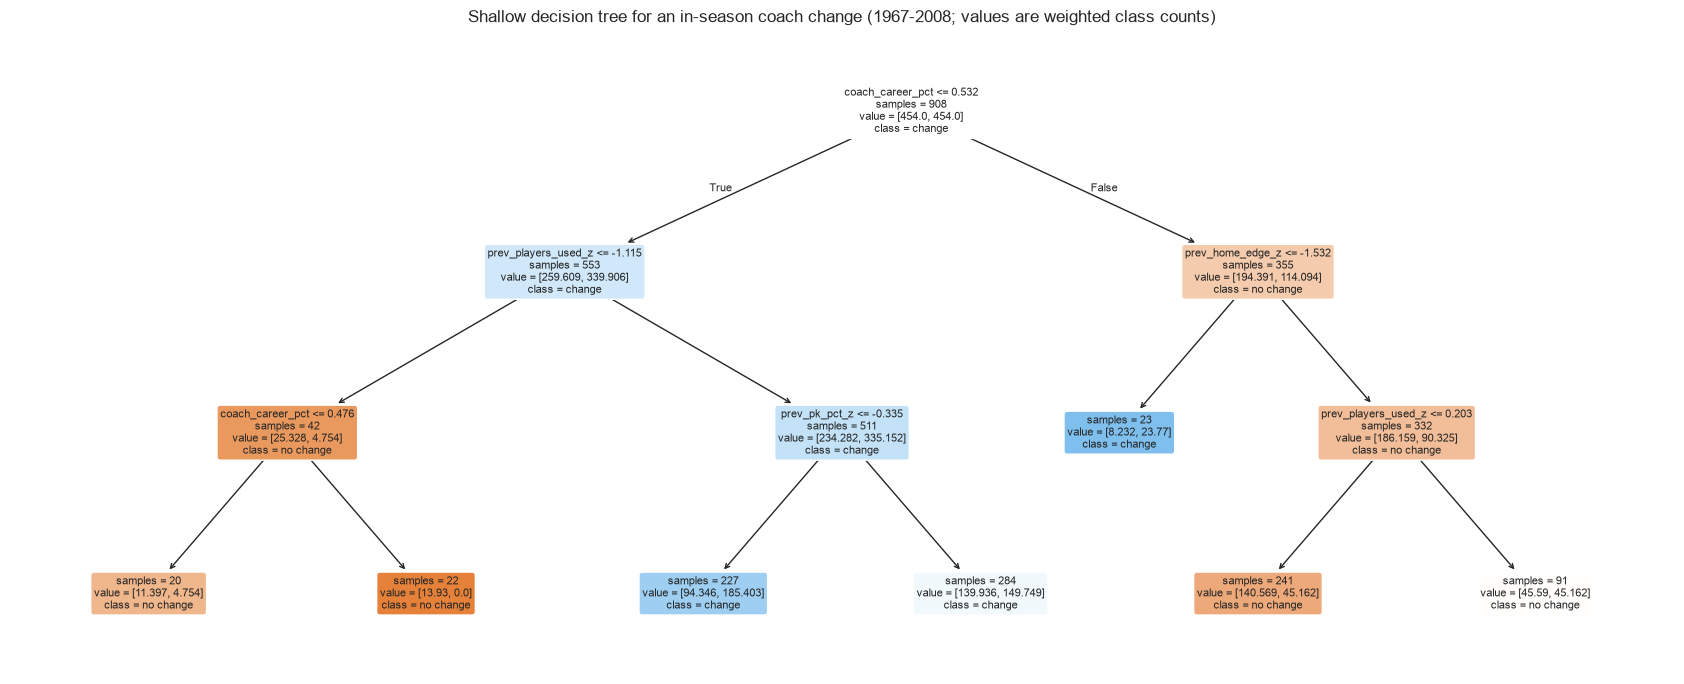

|--- coach_career_pct <= 0.53
|   |--- prev_players_used_z <= -1.12
|   |   |--- coach_career_pct <= 0.48
|   |   |   |--- class: 0
|   |   |--- coach_career_pct >  0.48
|   |   |   |--- class: 0
|   |--- prev_players_used_z >  -1.12
|   |   |--- prev_pk_pct_z <= -0.34
|   |   |   |--- class: 1
|   |   |--- prev_pk_pct_z >  -0.34
|   |   |   |--- class: 1
|--- coach_career_pct >  0.53
|   |--- prev_home_edge_z <= -1.53
|   |   |--- class: 1
|   |--- prev_home_edge_z >  -1.53
|   |   |--- prev_players_used_z <= 0.20
|   |   |   |--- class: 0
|   |   |--- prev_players_used_z >  0.20
|   |   |   |--- class: 0



,team-seasons,change rate
leaf,,
3,20,0.100
4,22,0.000
6,227,0.344
7,284,0.222
9,23,0.435
11,241,0.079
12,91,0.209


Depth-3 tree on the tuning seasons: PR-AUC 0.225, ROC-AUC 0.514, P@k 0.241


Depth-3 tree on the evaluation seasons: PR-AUC 0.246, ROC-AUC 0.585, P@k 0.360


In [16]:
X_imputed = pd.DataFrame(IterativeImputer(max_iter=10, random_state=SEED).fit_transform(known[FEATURES]), columns=FEATURES)
white = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight='balanced', random_state=SEED).fit(X_imputed, y_known)
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(white, feature_names=FEATURES, class_names=['no change', 'change'], filled=True, rounded=True, fontsize=8, impurity=False, ax=ax)
ax.set_title('Shallow decision tree for an in-season coach change (1967-2008; values are weighted class counts)')
plt.tight_layout()
plt.show()
print(export_text(white, feature_names=FEATURES))
leaves = pd.DataFrame({'leaf': white.apply(X_imputed), 'change': y_known}).groupby('leaf')['change'].agg(['size', 'mean'])
display(leaves.rename(columns={'size': 'team-seasons', 'mean': 'change rate'}).round(3))

small_tree = pipeline(DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight='balanced', random_state=SEED))
for label, seasons in [('tuning', TUNE), ('evaluation', EVAL)]:
    s = scores(predict_seasons(small_tree, seasons))
    print(f"Depth-3 tree on the {label} seasons: PR-AUC {s['PR-AUC pooled']:.3f}, ROC-AUC {s['ROC-AUC']:.3f}, P@k {s['P@k']:.3f}")

**What we found:** The depth-3 tree splits first on the coach's career points share (at 0.53), then on players used and the penalty kill. Change rates in its leaves:
- Coach with a career share of at most 0.53 and a very stable roster (players used below -1.12 SD): 0% of 22 and 10% of 20 teams.
- The same coach profile with a normal or large roster: 34.4% of 227 teams with a poor penalty kill (at most -0.34 SD), 22.2% of 284 with a better one.
- Coach with a career share above 0.53 and a poor home record (home edge at most -1.53 SD): 43.5% of 23 teams.
- Experienced, winning coach with a stable roster: 7.9% of 241 teams (20.9% of 91 with a larger roster).

Predictively the small tree is weak: pooled PR-AUC 0.225 on the tuning seasons and 0.246 on the evaluation seasons, close to the prevalence.

**Interpretation:** the rules agree with the other analyses (roster churn and a weak penalty kill raise the risk, a proven coach lowers it) and a club board can read them. The low-career branch also contains the first-time coaches, whose missing record is imputed with a low value. But the tree is too coarse to use as the predictor; the odds ratios of section 10 are the second white-box view.

## 12. Final test on 2009

Train the selected model once on all seasons 1967-2008 and predict the 30 teams of 2009 with the threshold of section 6, next to the baselines trained on the same rows. List all teams ranked by predicted probability and save the predictions to `data/processed/predictions_2009_coach.csv`.

This is the one clean test of the whole procedure on a season nobody looked at. With only a few changes in one season the metrics are very noisy, so it is a sanity check, not evidence about which model is better.

In [17]:
test_pred = baseline_predictions(TEST)
test_pred['Selected model'] = fit_predict(FINAL[SELECTED], TEST)
THRESHOLD['Selected model'] = THRESHOLD[SELECTED]
rows = {name: scores(p, THRESHOLD[name]) for name, p in test_pred.items()}
display(pd.DataFrame(rows).T[['PR-AUC pooled', 'ROC-AUC', 'Brier', 'precision', 'recall', 'F1', 'P@k', 'top-quarter share']].astype(float).round(3))

t = test_pred['Selected model'].join(d[['tmID', 'name']]).sort_values('p', ascending=False)
t['rank'] = np.arange(1, len(t) + 1)
t['flagged'] = (t['p'] >= THRESHOLD[SELECTED]).astype(int)
out = t[['year', 'tmID', 'name', 'p', 'rank', 'flagged', 'y']].rename(columns={'p': 'p_coach_change', 'y': 'actual_change'})
out.to_csv(ROOT / 'data' / 'processed' / 'predictions_2009_coach.csv', index=False)
display(out.round(3))
print(f"2009: {len(t)} teams, {int(t['y'].sum())} changes, prevalence {t['y'].mean():.3f}, k = {int(t['k'].iloc[0])}, "
      f"flagged at the threshold: {int(t['flagged'].sum())}")

,PR-AUC pooled,ROC-AUC,Brier,precision,recall,F1,P@k,top-quarter share
Majority (no change),0.100,0.500,0.100,0.000,0.000,0.000,0.100,0.267
Constant prevalence,0.100,0.500,0.102,0.000,0.000,0.000,0.100,0.267
Stratified random,0.104,0.519,0.333,0.111,0.333,0.167,0.111,0.296
Rule: low last-season points,0.127,0.414,NaN,0.000,0.000,0.000,0.000,0.000
Logistic: last-season points,0.127,0.414,0.101,0.000,0.000,0.000,0.000,0.000
Selected model,0.103,0.358,0.109,0.000,0.000,0.000,0.000,0.000


,year,tmID,name,p_coach_change,rank,flagged,actual_change
909,2009,ATL,Atlanta Thrashers,0.335,1,1,0
917,2009,DAL,Dallas Stars,0.312,2,1,0
935,2009,TOR,Toronto Maple Leafs,0.280,3,1,0
934,2009,TBL,Tampa Bay Lightning,0.279,4,1,0
910,2009,BOS,Boston Bruins,0.277,5,1,0
908,2009,AND,Anaheim Ducks,0.273,6,1,0
919,2009,EDM,Edmonton Oilers,0.259,7,1,0
916,2009,COL,Colorado Avalanche,0.257,8,1,0
926,2009,NYI,New York Islanders,0.203,9,0,0
937,2009,WAS,Washington Capitals,0.198,10,0,0


2009: 30 teams, 3 changes, prevalence 0.100, k = 6, flagged at the threshold: 8


**What we found:** 2009 had only 3 coach changes in 30 teams (prevalence 0.100, half the training rate; k = 6). The model flagged 8 teams (Atlanta, Dallas, Toronto, Tampa Bay, Boston, Anaheim, Edmonton, Colorado) and none of them changed coach. The three teams that did were ranked 13th (Philadelphia), 15th (St. Louis) and 30th (Columbus, the lowest probability). Pooled PR-AUC 0.103 (prevalence 0.100), ROC-AUC 0.358, Brier 0.109 against 0.102 for the constant prevalence. The baselines also catch nothing (one-feature logistic and rule: PR-AUC 0.127).

**Interpretation:** with 3 positives the test is almost uninformative: even 8 teams picked at random would miss all three changes about 38% of the time. It does not contradict the evaluation seasons; it only shows that the model has no strong skill in this one season, in which coaches were fired at a much lower rate than usual.

## 13. Conclusion

**Results on the evaluation seasons 2002-2008** (180 team-seasons, 36 changes)

| Model | Pooled PR-AUC | Mean per season ± sd | ROC-AUC | Precision@k | Top-quarter share | F1 at threshold |
|---|---|---|---|---|---|---|
| Majority / constant prevalence (no skill) | 0.200 / 0.195 | 0.200 ± 0.052 | 0.500 / 0.488 | 0.200 | 0.267 | 0 |
| Logistic regression on last-season points (baseline) | 0.310 | 0.392 ± 0.151 | 0.589 | 0.306 | 0.306 | 0.272 |
| Random forest | 0.301 | 0.375 ± 0.115 | 0.621 | 0.361 | 0.361 | 0.286 |
| SVM (RBF) | 0.288 | 0.368 ± 0.165 | 0.615 | 0.333 | 0.361 | 0.308 |
| **Gradient boosting (selected)** | **0.331** | **0.407 ± 0.158** | **0.634** | **0.361** | **0.417** | **0.381** |

Season 2009 (3 changes in 30 teams): no flagged team changed coach; pooled PR-AUC 0.103 against a prevalence of 0.100, an almost uninformative test.

**Decisions**

| # | Decision | Reason | Section |
|---|---|---|---|
| 1 | Pooled PR-AUC as main metric, with per-season PR-AUC, precision@k, top-quarter share, F1 and Brier; no accuracy | Prevalence 0.21; "never change" is 80% accurate and finds nothing | 1, 2 |
| 2 | Baseline: logistic regression on last-season points | It captures the obvious signal (PR-AUC 0.310) | 2 |
| 3 | Resampling only inside the training folds; best strategy per algorithm on the tuning seasons | SMOTE on the whole data inflated the forest from 0.269 to 0.646; on average no handling was best | 4 |
| 4 | Small grids on the tuning seasons, final model by best pooled PR-AUC with a per-season tie-break | Same type of rule as notebook 2; validation curves show overfitting beyond moderate complexity | 5 |
| 5 | Threshold: best F1 with at most 40% of the teams flagged | Without the limit boosting would flag 82% of the teams | 6 |
| 6 | Final model: gradient boosting (100 trees, depth 2, learning rate 0.1, threshold 0.237) | Best on the tuning seasons; best calibrated on the evaluation seasons | 5, 6, 7 |
| 7 | Report the gain over the baseline as not proven | Friedman p = 0.90; bootstrap +0.021, interval -0.129 to +0.158 | 7.2 |

**Business goals**
- **G2, anticipate in-season coach changes: met, narrowly.** PR-AUC 0.331 against the required 0.250, and 41.7% of the real changes in the riskiest quarter of teams against the required 40%. The one-feature baseline would not meet the second part (30.6%).
- **For a league office, an analyst or a club board:** about 36% of the 6 teams flagged each season really changed coach (random: 20%), and with the chosen threshold about 44% of all changes were caught at a precision of 0.33. That is a useful screening list, not a reliable alarm.
- **G3, explanations: met.** Conceding many goals, a weak penalty kill, many players used and a coach without a winning record raise the risk; deep playoff runs and a recent coach change lower it. Last season's luck hardly matters.

**Limitations**
- Only 36 changes in the evaluation seasons and 3 in the test season: the differences between models are within the noise and the tests have little power.
- The choices of notebook 1 (features, imputer, window) looked at seasons up to 2008, so the scores of the folds are slightly optimistic; 2009 was never used for a choice.
- The per-season tie-break of the selection rule was added after an earlier version of this notebook, in which the decision tree and boosting tied on the pooled PR-AUC. It uses tuning-season numbers only, and in this version boosting is best on the pooled PR-AUC alone, so it does not change the choice.
- A coach change means more than one coach stint in the season: offseason firings are not predicted, and some in-season changes (illness, scandals) are partly random.
- The base rate drifts (0.26 in the 1970s, about 0.20 since 1995, 0.10 in 2009).

**Where each rubric criterion is covered**

| Criterion | Where |
|---|---|
| Performance measure, interpretation of measures | 1, 7 |
| Baseline | 2 |
| Diversity of algorithms, understanding algorithm behaviour | 3, 5.1 |
| Imbalanced data (resampling, SMOTE used correctly) | 4, 4.1, 4.2 |
| Parameter tuning | 5, 5.1 |
| Other factors: time | 5 (grid search time, parallel) |
| Training vs test, analysis of results with significance tests | 7, 7.1, 7.2, 12 |
| Overfitting analysis | 5.1, 8, 8.1 |
| Model improvement | 9 |
| Feature importance | 10 |
| White-box models | 10 (odds ratios), 11 |

**Next steps:** notebook 4 selects features inside the folds (filter, then wrapper). This may help the models that overfit (SVM, forest, k-NN) and could reduce the 27 features to those found important here: goals against, roster use, penalty kill and coach history.